In [1]:
!pip -q install minisom gymnasium

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:
import os, glob, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.linalg import subspace_angles, orthogonal_procrustes
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
import tensorflow as tf
from tensorflow import keras

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [5]:
# --- locate the data ---------------------------------------------------------------------
# Running locally / from GitHub: download the "MetroPT-3 Dataset" (metropt_3_dataset.zip, UCI repository) and
#   (a) put the zip (or the extracted MetroPT3(AirCompressor).csv) next to this notebook or in ./data, or
#   (b) set DATA_PATH below, or the environment variable METROPT_PATH, to its location.
# Colab: set USE_DRIVE = True (zip on "My Drive"), drag the zip into /content, or use the upload dialog.
DATA_PATH = os.environ.get("METROPT_PATH")      # e.g. "data/metropt_3_dataset.zip"  (.zip or .csv)
USE_DRIVE = False                               # Colab only
DRIVE_ZIP = "/content/drive/MyDrive/metropt_3_dataset.zip"

if DATA_PATH is None and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_PATH = DRIVE_ZIP

if DATA_PATH is None:                           # look next to the notebook, in ./data and in /content
    found = []
    for d in [".", "data", "/content"]:
        for pat in ["*metropt*.zip", "*MetroPT*.zip", "*/*metropt*.zip", "*MetroPT*.csv", "*/*MetroPT*.csv"]:
            found += glob.glob(os.path.join(d, pat))
    if found:
        DATA_PATH = found[0]

if DATA_PATH is None:
    try:
        from google.colab import files
        DATA_PATH = list(files.upload().keys())[0]      # choose metropt_3_dataset.zip
    except ImportError:
        raise FileNotFoundError(
            "MetroPT-3 data not found. Download metropt_3_dataset.zip (UCI 'MetroPT-3 Dataset'), place it next to "
            "this notebook or in ./data, or set DATA_PATH / the METROPT_PATH environment variable.")
print("Using:", DATA_PATH)

if DATA_PATH.lower().endswith(".zip"):
    with zipfile.ZipFile(DATA_PATH) as zf:
        csv_name = [n for n in zf.namelist() if n.lower().endswith(".csv")][0]
        print("CSV inside zip:", csv_name)
        with zf.open(csv_name) as f:
            raw = pd.read_csv(f, parse_dates=["timestamp"])
else:
    raw = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])

raw = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")])
raw = raw.sort_values("timestamp").reset_index(drop=True)
print(raw.shape, "|", raw.timestamp.min(), "->", raw.timestamp.max())
raw.head()

Saving metropt+3+dataset.zip to metropt+3+dataset.zip
Using: metropt+3+dataset.zip
CSV inside zip: MetroPT3(AirCompressor).csv
(1516948, 16) | 2020-02-01 00:00:00 -> 2020-09-01 03:59:50


,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


**Commentary.** This confirms which file was read and how many raw rows it holds. Check that the printed time range covers all four failure windows (April to July 2020); if it does not, the labels built in the next step would be partly empty.

In [6]:
ANALOG  = ["TP2","TP3","H1","DV_pressure","Reservoirs","Oil_temperature","Motor_current"]
DIGITAL = ["COMP","DV_eletric","Towers","MPG","LPS","Pressure_switch","Oil_level","Caudal_impulses"]
FEATURES = ANALOG + DIGITAL

print("Missing values:", int(raw[FEATURES].isna().sum().sum()))
raw[FEATURES].describe().T.round(3)

Missing values: 0


,count,mean,std,min,25%,50%,75%,max
TP2,1516948.0,1.368,3.251,-0.032,-0.014,-0.012,-0.010,10.676
TP3,1516948.0,8.985,0.639,0.730,8.492,8.960,9.492,10.302
H1,1516948.0,7.568,3.333,-0.036,8.254,8.784,9.374,10.288
DV_pressure,1516948.0,0.056,0.382,-0.032,-0.022,-0.020,-0.018,9.844
Reservoirs,1516948.0,8.985,0.638,0.712,8.494,8.960,9.492,10.300
Oil_temperature,1516948.0,62.644,6.516,15.400,57.775,62.700,67.250,89.050
Motor_current,1516948.0,2.050,2.302,0.020,0.040,0.045,3.808,9.295
COMP,1516948.0,0.837,0.369,0.000,1.000,1.000,1.000,1.000
DV_eletric,1516948.0,0.161,0.367,0.000,0.000,0.000,0.000,1.000
Towers,1516948.0,0.920,0.272,0.000,1.000,1.000,1.000,1.000


**Commentary.** The missing-value count should be zero. The summary table shows the analog signals (pressures, oil temperature, motor current) on very different scales and the digital signals as 0/1 values, which is why the data is standardised before PCA, the AE and the SOM. Digital signals that are almost constant or that duplicate other signals add little independent information, so the data can be effectively lower-dimensional than the 15 columns suggest.

In [8]:
FAILURES = [
    ("2020-04-18 00:00", "2020-04-18 23:59"),
    ("2020-05-29 23:30", "2020-05-30 06:00"),
    ("2020-06-05 10:00", "2020-06-07 14:30"),
    ("2020-07-15 14:30", "2020-07-15 19:00"),
]
PRE_HOURS = 24

In [9]:
df = (raw.set_index("timestamp")[FEATURES].astype("float64")
         .resample("1min").mean().dropna())
print("1-min aggregated data:", df.shape)

# labels: 0 = normal, 1 = pre-failure (PRE_HOURS before a failure), 2 = failure
label = pd.Series(0, index=df.index, name="state")
for s, e in FAILURES:
    s, e = pd.Timestamp(s), pd.Timestamp(e)
    label[(df.index >= s - pd.Timedelta(hours=PRE_HOURS)) & (df.index < s)] = 1
    label[(df.index >= s) & (df.index <= e)] = 2
names = {0: "Normal", 1: f"Pre-failure ({PRE_HOURS}h)", 2: "Failure"}
print(label.map(names).value_counts())

y = label.values
abn = (y > 0).astype(int); fail = (y == 2).astype(int)

# --- train / validation / test split ----------------------------------------------------------
# Everything that is *fitted* (scaler, PCA, autoencoders, SOM) only ever sees NORMAL minutes. Normal minutes are
# split in whole-day blocks (random, seeded) so that neighbouring, highly correlated minutes do not leak across
# the split and the validation set is not simply "the last 10 % of the rows".
day = df.index.floor("D")
days = day.unique()
role = pd.Series(np.random.default_rng(SEED).choice(["train", "val", "test"], size=len(days), p=[0.8, 0.1, 0.1]),
                 index=days)
role_min = role.reindex(day).values
normal = y == 0
train_mask = normal & (role_min == "train")
val_mask   = normal & (role_min == "val")
test_mask  = normal & (role_min == "test")
eval_mask  = (y > 0) | test_mask        # scoring set: held-out normal minutes + all abnormal minutes (never fitted on)
print(f"normal minutes -> train {train_mask.sum():,} | val {val_mask.sum():,} | test {test_mask.sum():,}")

scaler = StandardScaler().fit(df.values[train_mask])
X = scaler.transform(df.values)                      # float64
X_tr, X_va, X_te = X[train_mask], X[val_mask], X[test_mask]
print("X:", X.shape)

def auc_abn(e):  return roc_auc_score(abn[eval_mask],  e[eval_mask])    # pre-failure+failure vs held-out normal
def auc_fail(e): return roc_auc_score(fail[eval_mask], e[eval_mask])    # failure vs held-out normal + pre-failure

1-min aggregated data: (252720, 15)
state
Normal               242863
Failure                4960
Pre-failure (24h)      4897
Name: count, dtype: int64
normal minutes -> train 196,770 | val 24,687 | test 21,406
X: (252720, 15)


**Commentary.** The class counts show how rare the abnormal minutes are compared with normal operation, so accuracy-type metrics would be misleading and ROC-AUC is used instead. The split line shows how the normal minutes were divided into train, validation and test by whole day. The shares are only approximately 80/10/10 because days are assigned at random. Failure and pre-failure minutes appear in none of the three sets, so nothing that is fitted has seen them.

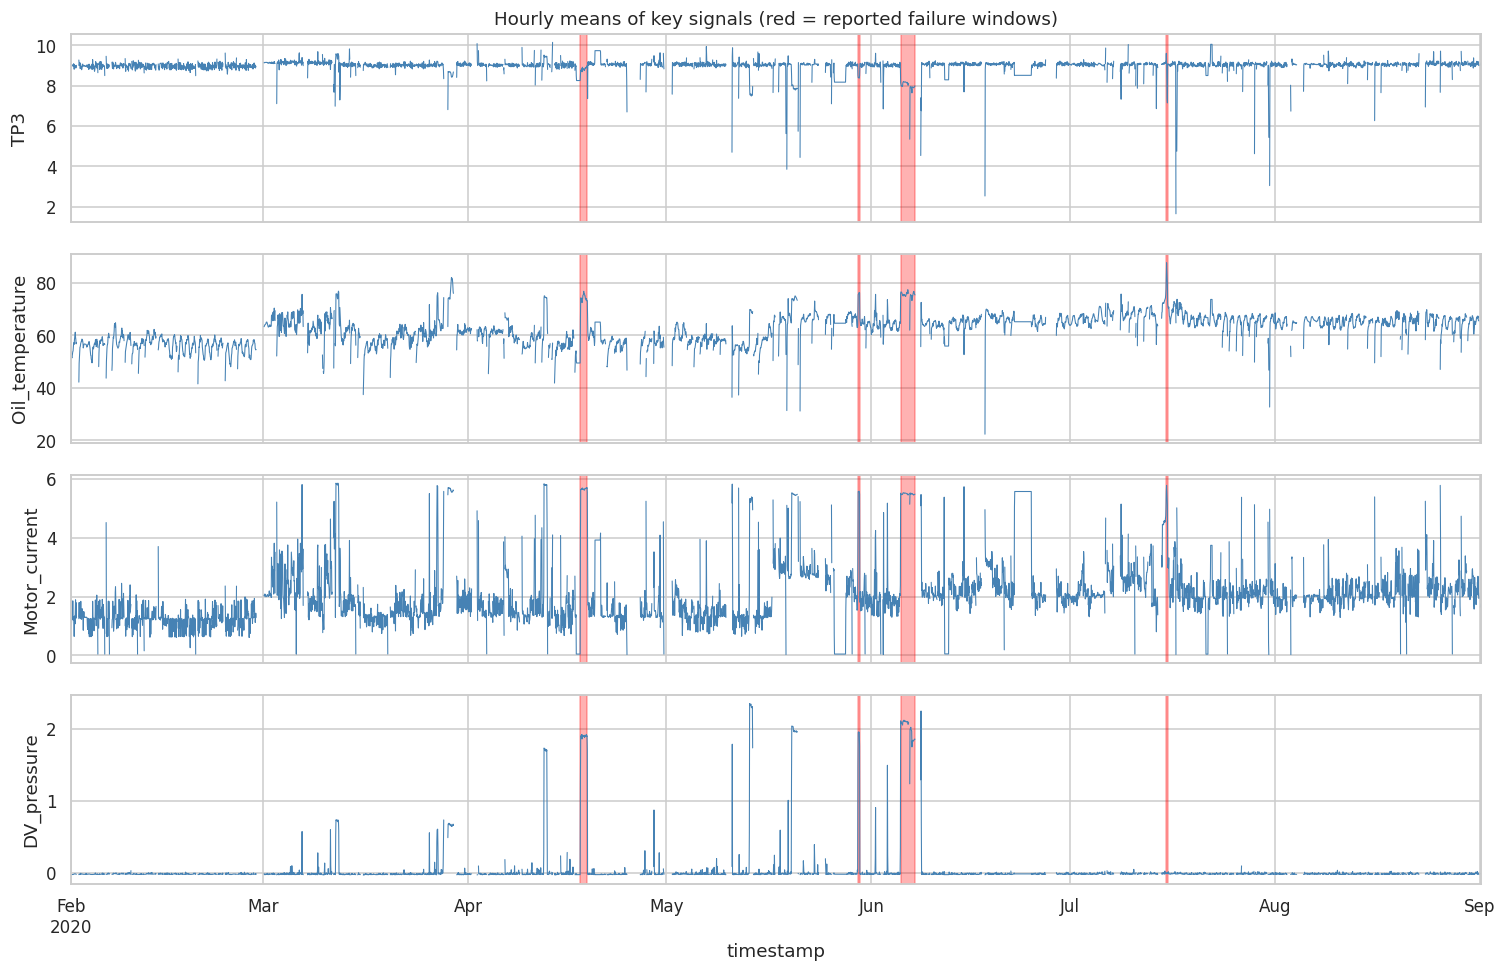

In [10]:
# Overview of the signals with the failure windows shaded
fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
for ax, col in zip(axes, ["TP3", "Oil_temperature", "Motor_current", "DV_pressure"]):
    df[col].resample("1h").mean().plot(ax=ax, lw=0.7, color="steelblue")
    ax.set_ylabel(col)
    for s, e in FAILURES:
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color="red", alpha=0.3)
axes[0].set_title("Hourly means of key signals (red = reported failure windows)")
plt.tight_layout(); plt.show()

**Commentary.** The red bands are the reported failure windows. Look for drift or changes in the signals in the hours before each band. If a signal looks normal right up to the failure, an unsupervised detector has little to find in it. Operating-mode changes visible outside the bands show that a deviation from normal is not always a fault.

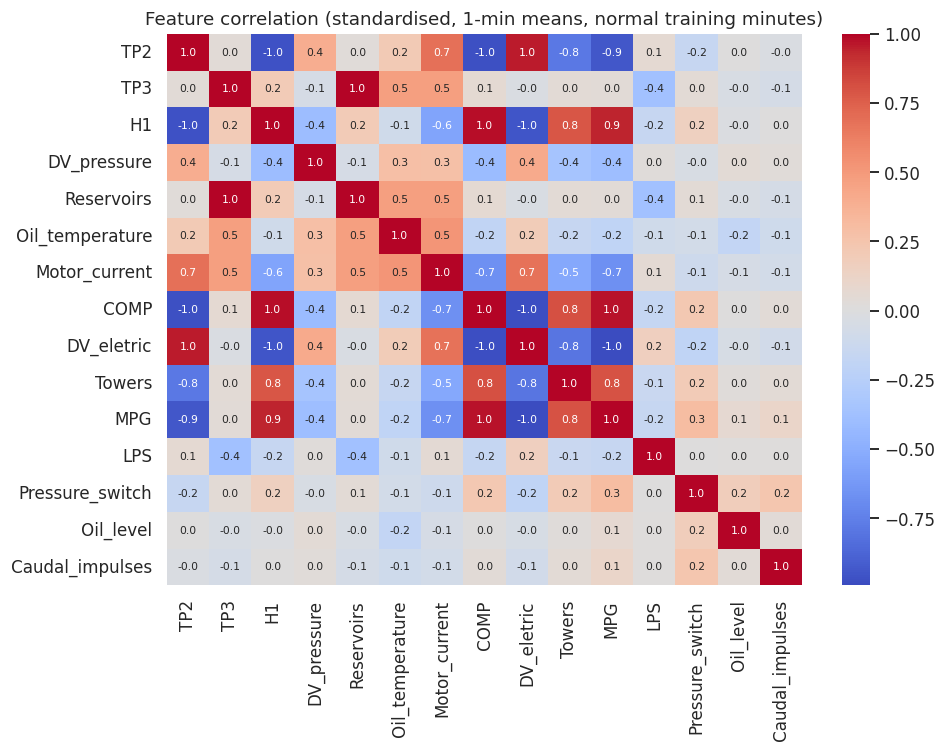

In [11]:
plt.figure(figsize=(9, 7))
sns.heatmap(pd.DataFrame(X_tr, columns=FEATURES).corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Feature correlation (standardised, 1-min means, normal training minutes)"); plt.tight_layout(); plt.show()

**Commentary.** Blocks of high absolute correlation show signals that move together. This redundancy is why a few components can capture most of the variance, and why the high-k reconstruction error later becomes numerically tiny. The matrix is computed on normal training minutes only.

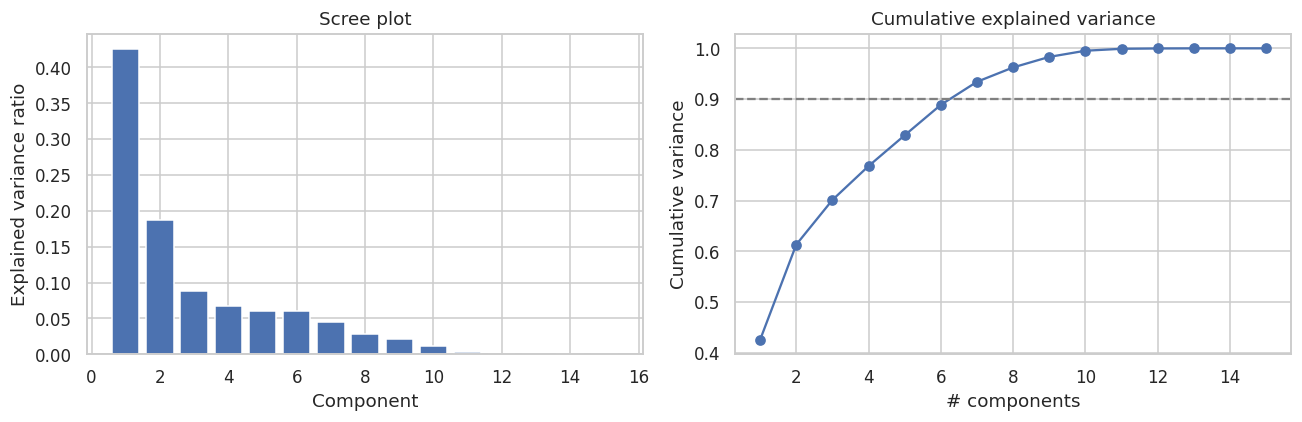

Variance explained by PC1, PC2: [0.425 0.188] | total (2 PCs): 0.613


In [12]:
pca_full = PCA().fit(X_tr)
evr = pca_full.explained_variance_ratio_

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, len(evr)+1), evr); ax[0].set_xlabel("Component"); ax[0].set_ylabel("Explained variance ratio")
ax[0].set_title("Scree plot")
ax[1].plot(range(1, len(evr)+1), np.cumsum(evr), "o-"); ax[1].axhline(0.9, ls="--", c="grey")
ax[1].set_xlabel("# components"); ax[1].set_ylabel("Cumulative variance"); ax[1].set_title("Cumulative explained variance")
plt.tight_layout(); plt.show()
print("Variance explained by PC1, PC2:", evr[:2].round(3), "| total (2 PCs):", evr[:2].sum().round(3))

**Commentary.** The left panel shows how variance is spread across components, and the right panel shows the cumulative curve with the 90% line. The number of PCs used later (`best_k`) is read from this curve on normal training data, with no failure labels involved. The printed PC1/PC2 shares are how much of the variance the 2-D pictures can show.

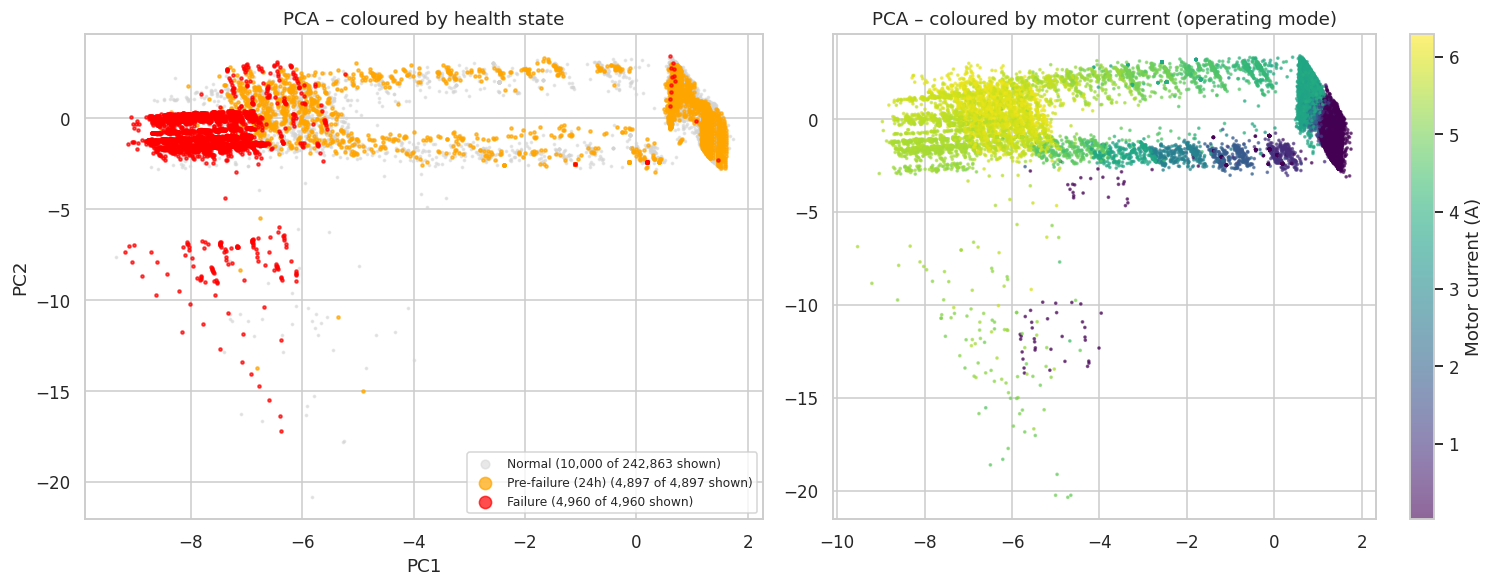

In [13]:
pca = PCA(n_components=2, random_state=SEED).fit(X_tr)
Z_pca = pca.transform(X)

# --- plotting helpers: every plot draws the SAME number of points per health state -------------
# Each helper owns a seeded generator, so re-running cells in any order gives identical samples.
def sample_by_state(per_class, seed):
    r = np.random.default_rng(seed)
    return {k: r.choice(np.where(y == k)[0], size=min(per_class, int((y == k).sum())), replace=False) for k in (0, 1, 2)}

def scatter_states(Z, ax, title, xlabel="dim 1", ylabel="dim 2", per_class=10000, seed=SEED):
    idx = sample_by_state(per_class, seed)
    style = {0: ("lightgrey", 2, 0.5), 1: ("orange", 4, 0.7), 2: ("red", 4, 0.7)}      # abnormal drawn last (on top)
    for k, (col, s, a) in style.items():
        ax.scatter(Z[idx[k], 0], Z[idx[k], 1], s=s, c=col, alpha=a,
                   label=f"{names[k]} ({len(idx[k]):,} of {(y == k).sum():,} shown)")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)

def scatter_motor(Z, ax, title, n=40000, seed=SEED):
    idx = np.random.default_rng(seed).choice(len(Z), size=min(n, len(Z)), replace=False)
    sc = ax.scatter(Z[idx, 0], Z[idx, 1], s=2, c=df["Motor_current"].values[idx], cmap="viridis", alpha=0.6)
    plt.colorbar(sc, ax=ax, label="Motor current (A)"); ax.set_title(title)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
scatter_states(Z_pca, ax[0], "PCA – coloured by health state", "PC1", "PC2"); ax[0].legend(markerscale=4, fontsize=8)
scatter_motor(Z_pca, ax[1], "PCA – coloured by motor current (operating mode)")
plt.tight_layout(); plt.show()

**Commentary.** Each health state is drawn with the same number of points, and the legend shows how many of each were plotted. Orange and red points sitting inside the grey cloud mean the first two PCs do not separate pre-failure or failure minutes by position alone. The right panel colours the same points by motor current, which is a proxy for operating mode. If the main structure follows motor current, the dominant variation in 2-D is the operating regime and not a developing fault.

In [14]:
# What do the components mean? (loadings)
load = pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"])
load.sort_values("PC1", key=np.abs, ascending=False).round(3).style.background_gradient(cmap="coolwarm", axis=None)

,PC1,PC2
COMP,0.390000,0.058000
DV_eletric,-0.388000,-0.038000
MPG,0.387000,0.042000
TP2,-0.383000,-0.002000
H1,0.376000,0.137000
Towers,0.335000,0.050000
Motor_current,-0.292000,0.296000
DV_pressure,-0.188000,-0.004000
Oil_temperature,-0.114000,0.381000
Pressure_switch,0.097000,0.017000


**Commentary.** The table lists which sensors drive PC1 and PC2, sorted by absolute weight on PC1. Use it to give the axes a physical meaning. Large weights on a few related signals mean the component mostly tracks one subsystem or one operating mode.

Epochs run: 10 | best val MSE: 0.2003


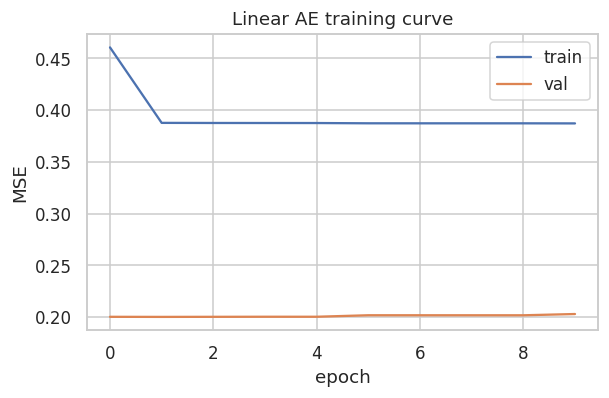

In [15]:
def build_linear_ae(n_in, n_latent, name="linear_ae"):
    inp = keras.Input(shape=(n_in,))
    z = keras.layers.Dense(n_latent, activation=None, name="encoder")(inp)
    out = keras.layers.Dense(n_in, activation=None, name="decoder")(z)
    ae = keras.Model(inp, out, name=name)
    enc = keras.Model(inp, z, name="enc")
    ae.compile(optimizer=keras.optimizers.Adam(1e-2), loss="mse")
    return ae, enc

# ONE training recipe for every autoencoder in this notebook (k=2, the sweep, and the best-k model), so that
# AE-vs-PCA comparisons are like for like. Fit on normal training minutes, early-stop on held-out normal days.
AE_EPOCHS, AE_PATIENCE, AE_BATCH = 60, 8, 512

def train_linear_ae(k, seed):
    keras.utils.set_random_seed(seed)        # own seed per model -> result does not depend on execution order
    ae, enc = build_linear_ae(X.shape[1], k, name=f"linear_ae_{k}")
    cb = [keras.callbacks.EarlyStopping(patience=AE_PATIENCE, restore_best_weights=True, monitor="val_loss"),
          keras.callbacks.ReduceLROnPlateau(patience=4, factor=0.5, monitor="val_loss")]
    hist = ae.fit(X_tr, X_tr, epochs=AE_EPOCHS, batch_size=AE_BATCH, validation_data=(X_va, X_va),
                  shuffle=True, callbacks=cb, verbose=0)
    return ae, enc, hist

# A linear AE is just two affine maps, so encoding / reconstruction is done directly from the weights in numpy.
# (Calling .predict() on many freshly built models in a loop triggers TensorFlow retracing warnings.)
def ae_encode(ae, data):
    We, be = ae.get_layer("encoder").get_weights()
    return data @ We + be

def ae_reconstruct(ae, data):
    Wd, bd = ae.get_layer("decoder").get_weights()
    return ae_encode(ae, data) @ Wd + bd

ae2, enc2, hist = train_linear_ae(2, SEED)
print("Epochs run:", len(hist.history["loss"]), "| best val MSE:", round(float(min(hist.history["val_loss"])), 4))

plt.figure(figsize=(6, 3.5))
plt.plot(hist.history["loss"], label="train"); plt.plot(hist.history["val_loss"], label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Linear AE training curve"); plt.legend(); plt.show()

Z_ae = ae_encode(ae2, X)

**Commentary.** The printout gives the epochs actually run and the best validation MSE, measured on held-out normal days. Train and validation curves that are close and flat at the end indicate convergence without overfitting. For a linear model with so few parameters, a large gap would point to a distribution shift between train and validation days. Stopping well before 60 epochs means early stopping triggered.

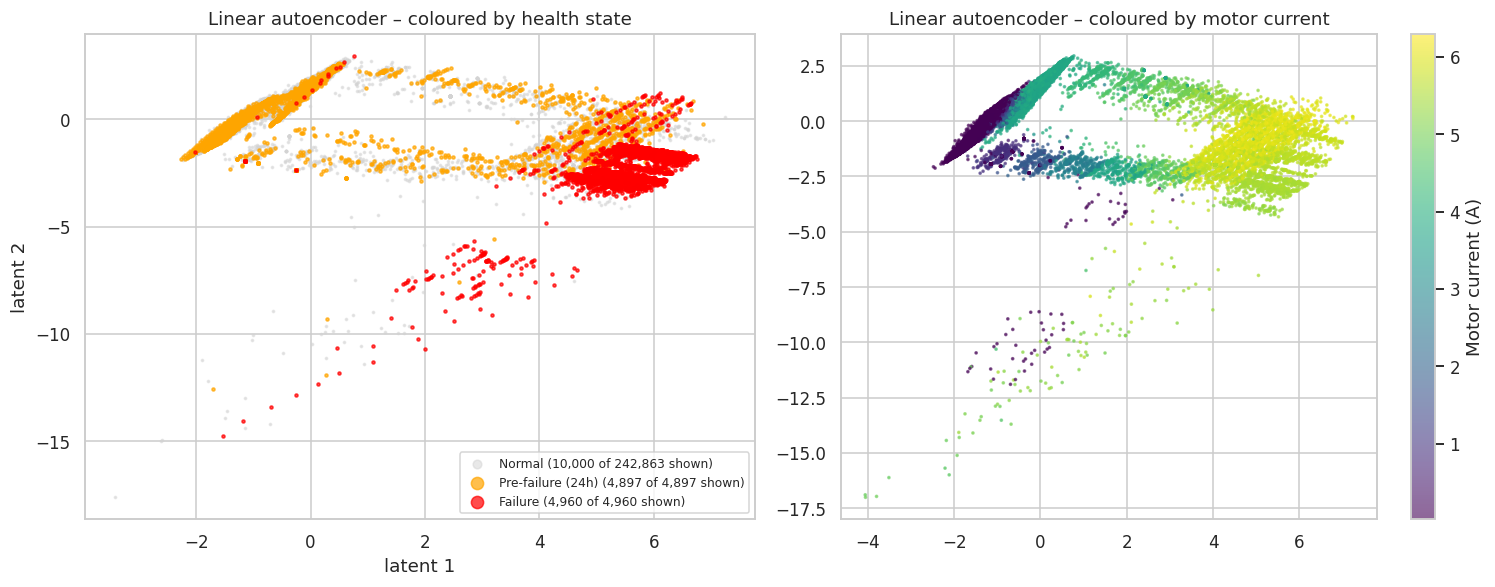

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
scatter_states(Z_ae, ax[0], "Linear autoencoder – coloured by health state", "latent 1", "latent 2"); ax[0].legend(markerscale=4, fontsize=8)
scatter_motor(Z_ae, ax[1], "Linear autoencoder – coloured by motor current")
plt.tight_layout(); plt.show()

**Commentary.** The AE latent axes are an arbitrary linear mix of the principal directions, so the picture can look rotated, sheared or flipped compared with PCA even when the subspace is identical. Do not judge similarity from this plot. The principal angles and the rotation-only comparison in the next cells are the proper test.

In [17]:
# 1. reconstruction error on held-out normal days
X_rec_pca = pca.inverse_transform(Z_pca)
X_rec_ae  = ae_reconstruct(ae2, X)
mse_pca = np.mean((X_te - X_rec_pca[test_mask]) ** 2); mse_ae = np.mean((X_te - X_rec_ae[test_mask]) ** 2)

# 2. principal angles between the 2-D subspaces  <- the real test of "do PCA and the AE find the same subspace?"
W_dec = ae2.get_layer("decoder").get_weights()[0]          # (2, n_features): rows span the AE subspace
angles = np.degrees(subspace_angles(pca.components_.T, W_dec.T))

# 3. correlation of AE latents with PC scores
corr = np.corrcoef(np.c_[Z_ae, Z_pca].T)[:2, 2:]

print(f"Reconstruction MSE (held-out normal) – PCA(2): {mse_pca:.4f} | Linear AE(2): {mse_ae:.4f}")
print("Principal angles between subspaces (deg):", angles.round(2))
print("|corr| AE latents (rows) vs PCs (cols):\n", np.abs(corr).round(3))

Reconstruction MSE (held-out normal) – PCA(2): 0.5369 | Linear AE(2): 0.5312
Principal angles between subspaces (deg): [3.58 1.12]
|corr| AE latents (rows) vs PCs (cols):
 [[0.958 0.25 ]
 [0.419 0.922]]


**Commentary.** PCA is the optimal 2-D linear reconstruction, so the AE's held-out MSE can approach but not meaningfully beat it. The principal angles are the main result: angles near 0° mean the AE found the same plane as PCA, and large angles mean a different plane or an unconverged fit. The correlation matrix is not expected to be an identity matrix, because each AE latent is a mixture of PC1 and PC2.

Relative Procrustes residual (0 = identical maps): 0.0202  | principal angles (deg): [3.58 1.12]


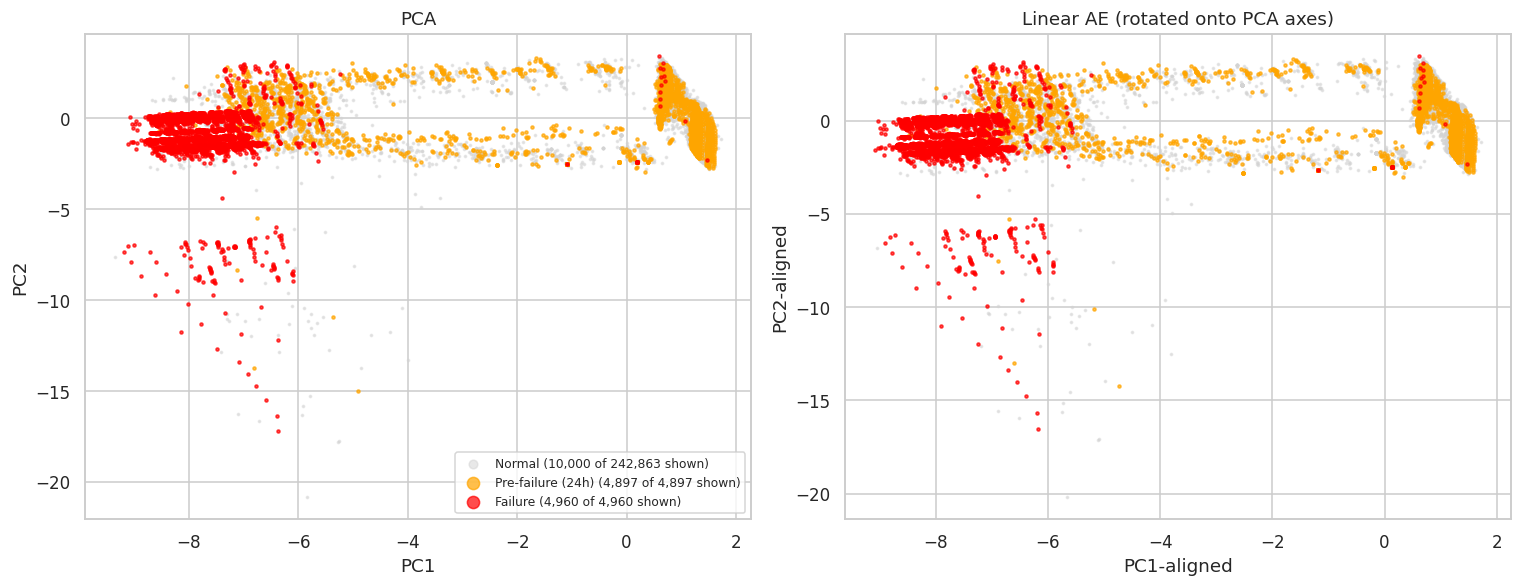

In [18]:
# Compare the AE and PCA maps WITHOUT forcing them to agree.
# The AE subspace is projected orthogonally (orthonormal basis of the decoder's row space) and then only ROTATED /
# reflected onto the PCA axes (orthogonal Procrustes: no stretching or shearing). A general least-squares linear map
# would make the plots look alike by construction; a pure rotation looks alike only if the subspaces really agree.
Q_ae, _ = np.linalg.qr(W_dec.T)                               # (n_features, 2) orthonormal basis of the AE subspace
Z_ae_sub = (X - pca.mean_) @ Q_ae
R, _ = orthogonal_procrustes(Z_ae_sub[train_mask], Z_pca[train_mask])
Z_ae_aligned = Z_ae_sub @ R
rel_resid = np.linalg.norm(Z_ae_aligned[train_mask] - Z_pca[train_mask]) / np.linalg.norm(Z_pca[train_mask])
print(f"Relative Procrustes residual (0 = identical maps): {rel_resid:.4f}  | principal angles (deg): {angles.round(2)}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
scatter_states(Z_pca, ax[0], "PCA", "PC1", "PC2")
scatter_states(Z_ae_aligned, ax[1], "Linear AE (rotated onto PCA axes)", "PC1-aligned", "PC2-aligned")
ax[0].legend(markerscale=4, fontsize=8); plt.tight_layout(); plt.show()

**Commentary.** The AE plane is projected orthogonally and then only rotated or reflected onto the PCA axes, with no stretching, so the two plots look alike only if the subspaces really agree. A small relative residual together with small principal angles supports "same subspace". A large residual means the plots differ for a real reason.

,PCA_MSE,LinearAE_MSE
latent_dim,,
1,0.6908,0.6911
2,0.5369,0.5385
3,0.4147,0.4112
4,0.3354,0.3355
6,0.1578,0.1601
8,0.0460,0.0467


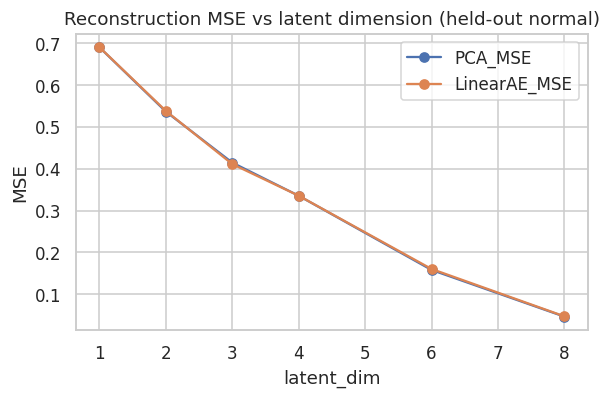

In [20]:
# How does reconstruction error behave with the bottleneck size? (PCA vs linear AE, same recipe, held-out normal days)
rows = []
for k in [1, 2, 3, 4, 6, 8]:
    p = PCA(n_components=k).fit(X_tr)
    e_p = np.mean((X_te - p.inverse_transform(p.transform(X_te))) ** 2)
    a, _, _ = train_linear_ae(k, SEED + k)
    e_a = np.mean((X_te - ae_reconstruct(a, X_te)) ** 2)
    rows.append((k, e_p, e_a))
sweep = pd.DataFrame(rows, columns=["latent_dim", "PCA_MSE", "LinearAE_MSE"]).set_index("latent_dim")
display(sweep.round(4))
sweep.plot(marker="o", figsize=(6, 3.5), title="Reconstruction MSE vs latent dimension (held-out normal)"); plt.ylabel("MSE"); plt.show()

**Commentary.** PCA is the reference curve, since it is the optimum for each k, and the AE should follow it from above with the same training recipe at every k. A gap that grows with k suggests the AE needs more epochs there. Errors flatten once the main structure is covered, which is the diminishing-returns point for choosing a bottleneck size.

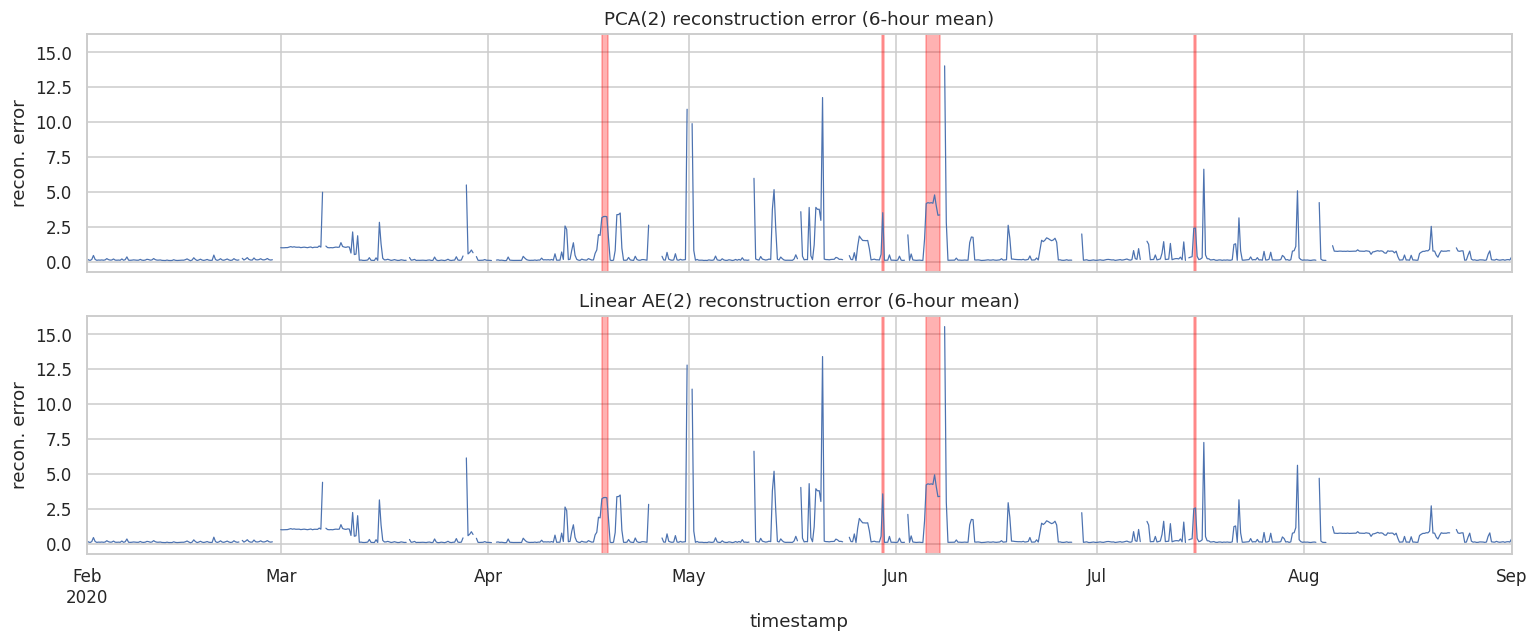

PCA(2)        ROC-AUC  abnormal-vs-normal: 0.730 | failure-vs-normal: 0.959
Linear AE(2)  ROC-AUC  abnormal-vs-normal: 0.729 | failure-vs-normal: 0.959


In [21]:
err_pca = np.mean((X - X_rec_pca) ** 2, axis=1)
err_ae  = np.mean((X - X_rec_ae)  ** 2, axis=1)

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True, sharey=True)
for ax, e, t in zip(axes, [err_pca, err_ae], ["PCA(2)", "Linear AE(2)"]):
    pd.Series(e, index=df.index).resample("6h").mean().plot(ax=ax, lw=0.8)
    ax.set_ylabel("recon. error"); ax.set_title(f"{t} reconstruction error (6-hour mean)")
    for s, en in FAILURES:
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(en), color="red", alpha=0.3)
plt.tight_layout(); plt.show()

# AUCs use held-out normal minutes + all abnormal minutes (nothing here was used to fit the models)
for n, e in [("PCA(2)", err_pca), ("Linear AE(2)", err_ae)]:
    print(f"{n:13s} ROC-AUC  abnormal-vs-normal: {auc_abn(e):.3f} | failure-vs-normal: {auc_fail(e):.3f}")

**Commentary.** Both panels share the y-axis, so the heights of the two error curves can be compared directly. Look at whether the error rises inside or just before the red windows, and also at how often it rises at other times, since those are false alarms. A rise can also come from a change of operating mode and not from a fault. The AUCs printed below use only held-out normal days and abnormal minutes, so they are not inflated by training data. An AUC near 0.5 means no better than chance.

,cum_variance,train_MSE,test_MSE,AUC_failure,AUC_abnormal
n_components,,,,,
2,0.613,0.387,0.537,0.959,0.73
3,0.701,0.299,0.415,0.972,0.732
4,0.768,0.232,0.335,0.973,0.748
5,0.829,0.171,0.262,0.971,0.75
6,0.889,0.111,0.158,0.841,0.688
8,0.962,0.0376,0.046,0.83,0.676
10,0.995,0.00471,0.00348,0.716,0.617
12,1,0.000249,0.000266,0.84,0.705
14,1,2.18e-07,2.09e-07,nan,nan


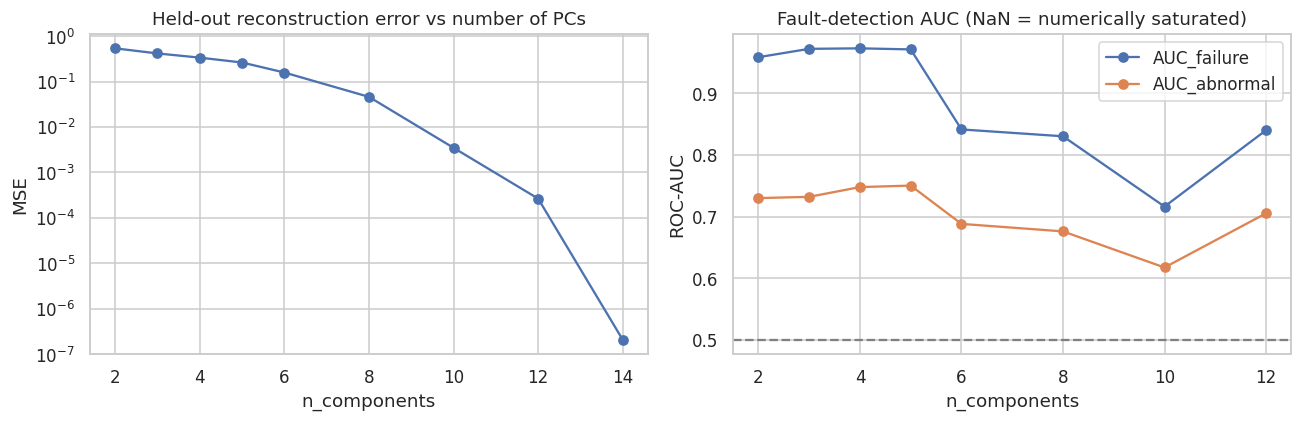

Chosen number of PCs (smallest k with >= 90% cumulative variance on normal training data): 7


In [22]:
# Sweep over the number of PCs. Everything is computed in float64 on a model fitted on normal training minutes only.
# Once k is large enough to reconstruct the normal data almost exactly, the residual is rounding noise and an AUC
# computed from it is meaningless -> those AUCs are set to NaN instead of being reported.
NOISE_TOL = 1e-6          # train-MSE below this = numerically saturated
rows = []
for k in [2, 3, 4, 5, 6, 8, 10, 12, 14]:
    p = PCA(n_components=k).fit(X_tr)
    e = np.mean((X - p.inverse_transform(p.transform(X))) ** 2, axis=1)
    saturated = e[train_mask].mean() < NOISE_TOL
    rows.append(dict(n_components=k, cum_variance=p.explained_variance_ratio_.sum(),
                     train_MSE=e[train_mask].mean(), test_MSE=e[test_mask].mean(),
                     AUC_failure=np.nan if saturated else auc_fail(e),
                     AUC_abnormal=np.nan if saturated else auc_abn(e)))
pcs_sweep = pd.DataFrame(rows).set_index("n_components")
display(pcs_sweep.style.format("{:.3g}"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pcs_sweep["test_MSE"].plot(marker="o", ax=ax[0], title="Held-out reconstruction error vs number of PCs"); ax[0].set_ylabel("MSE"); ax[0].set_yscale("log")
pcs_sweep[["AUC_failure", "AUC_abnormal"]].plot(marker="o", ax=ax[1], title="Fault-detection AUC (NaN = numerically saturated)")
ax[1].axhline(0.5, ls="--", c="grey"); ax[1].set_ylabel("ROC-AUC")
plt.tight_layout(); plt.show()

# k is chosen WITHOUT looking at the failure labels: smallest k reaching the cumulative-variance target on the
# normal training data. The AUC columns above are reported, never used for selection.
VAR_TARGET = 0.90
best_k = int(np.searchsorted(np.cumsum(evr), VAR_TARGET) + 1)
print(f"Chosen number of PCs (smallest k with >= {VAR_TARGET:.0%} cumulative variance on normal training data): {best_k}")

**Commentary.** `train_MSE` shrinking towards zero marks where the normal data is reconstructed almost exactly. AUCs there are set to NaN because the residual is rounding noise. Similar `train_MSE` and `test_MSE` mean the PCA subspace generalises across days. The AUC columns are diagnostics only and were not used to choose k. The chosen k comes from the variance rule printed at the bottom, so it does not use the failure labels.

In [23]:
# Linear AE vs PCA at several k (2, 4 and the chosen best_k), 5 training seeds per AE, same recipe everywhere.
# For every AE we report: principal angles to the PCA subspace, held-out MSE, AUCs of the AE's own reconstruction error,
# and the AUC of the error of an orthogonal projection onto the AE's decoder subspace ("proj"). If "proj" matches PCA
# while the AE's own error does not, the subspace is right and the difference comes from the AE's encoder/bias not
# having fully converged to the orthogonal projection; if "proj" is also worse, the AE found a different subspace.
AE_SEEDS = [SEED + i for i in range(5)]
ks_cmp = sorted({2, 4, best_k})
mu_tr = X_tr.mean(axis=0)

def proj_error(Wd, data):
    Qb_, _ = np.linalg.qr(Wd.T)                       # orthonormal basis of the decoder's row space
    Xc = data - mu_tr
    return np.mean((Xc - (Xc @ Qb_) @ Qb_.T) ** 2, axis=1)

rows = []
for k in ks_cmp:
    pk = PCA(n_components=k).fit(X_tr)
    e_pk = np.mean((X - pk.inverse_transform(pk.transform(X))) ** 2, axis=1)
    rows.append(dict(k=k, model="PCA", seed=-1, epochs=np.nan, max_angle_deg=0.0, mean_angle_deg=0.0,
                     test_MSE=e_pk[test_mask].mean(), AUC_failure=auc_fail(e_pk), AUC_abnormal=auc_abn(e_pk),
                     AUC_failure_proj=auc_fail(e_pk)))
    for i, sd in enumerate(AE_SEEDS):
        a, _, h = train_linear_ae(k, sd + 100 * k)
        Wd = a.get_layer("decoder").get_weights()[0]
        ang = np.degrees(subspace_angles(pk.components_.T, Wd.T))
        e_a = np.mean((X - ae_reconstruct(a, X)) ** 2, axis=1)
        rows.append(dict(k=k, model="Linear AE", seed=sd, epochs=len(h.history["loss"]),
                         max_angle_deg=ang.max(), mean_angle_deg=ang.mean(),
                         test_MSE=e_a[test_mask].mean(), AUC_failure=auc_fail(e_a), AUC_abnormal=auc_abn(e_a),
                         AUC_failure_proj=auc_fail(proj_error(Wd, X))))
cmp_runs = pd.DataFrame(rows)
cols = ["epochs", "max_angle_deg", "mean_angle_deg", "test_MSE", "AUC_failure", "AUC_abnormal", "AUC_failure_proj"]
cmp_summary = cmp_runs.groupby(["k", "model"])[cols].agg(["mean", "std"])
display(cmp_runs[cmp_runs.k == best_k].set_index(["model", "seed"]).drop(columns="k").round(4))
display(cmp_summary.round(4))

epochs  max_angle_deg  mean_angle_deg  test_MSE  AUC_failure  \
model     seed                                                                 
PCA       -1       NaN         0.0000          0.0000    0.0856       0.9270   
Linear AE  42     20.0         2.6612          1.0076    0.0895       0.9317   
           43     16.0         3.8603          0.8991    0.0905       0.9469   
           44     26.0         2.9915          0.9916    0.0895       0.9429   
           45     26.0         1.7076          0.5297    0.0866       0.9382   
           46     60.0         0.0539          0.0154    0.0856       0.9265   

                AUC_abnormal  AUC_failure_proj  
model     seed                                  
PCA       -1          0.7554            0.9270  
Linear AE  42         0.7543            0.9318  
           43         0.7610            0.9474  
           44         0.7614            0.9434  
           45         0.7615            0.9381  
           46         0.7552            0.9265

epochs          max_angle_deg         mean_angle_deg          \
              mean      std          mean     std           mean     std   
k model                                                                    
2 Linear AE   33.2  25.4892        1.3260  1.4066         0.9393  0.9599   
  PCA          NaN      NaN        0.0000     NaN         0.0000     NaN   
4 Linear AE   24.6  20.1693        3.1501  1.9370         1.3287  0.7570   
  PCA          NaN      NaN        0.0000     NaN         0.0000     NaN   
7 Linear AE   29.6  17.5157        2.2549  1.4516         0.6887  0.4232   
  PCA          NaN      NaN        0.0000     NaN         0.0000     NaN   

            test_MSE         AUC_failure         AUC_abnormal          \
                mean     std        mean     std         mean     std   
k model                                                                 
2 Linear AE   0.5389  0.0045      0.9589  0.0007       0.7299  0.0004   
  PCA         0.5369     NaN      0.9586     NaN       0.7299     NaN   
4 Linear AE   0.3358  0.0009      0.9729  0.0001       0.7476  0.0019   
  PCA         0.3354     NaN      0.9729     NaN       0.7478     NaN   
7 Linear AE   0.0883  0.0021      0.9372  0.0083       0.7587  0.0036   
  PCA         0.0856     NaN      0.9270     NaN       0.7554     NaN   

            AUC_failure_proj          
                        mean     std  
k model                               
2 Linear AE           0.9588  0.0006  
  PCA                 0.9586     NaN  
4 Linear AE           0.9728  0.0001  
  PCA                 0.9729     NaN  
7 Linear AE           0.9374  0.0085  
  PCA                 0.9270     NaN

**Commentary.** The first table shows each AE seed at the chosen k and the second summarises mean and std by k and model (PCA is deterministic, so it has no std). Read it in this order. First, `max_angle_deg` says whether the AE found the PCA subspace. Second, if the angle is small and `AUC_failure` is still lower than PCA's, compare `AUC_failure_proj`: if that matches PCA, the plane is right and the loss comes from the AE's encoder and bias not reaching the orthogonal projection. Third, if the angle is large, the AE learned a different subspace. A gap smaller than the seed std is not a real difference. `epochs` shows whether early stopping cut training short.

In [24]:
from minisom import MiniSom
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# SOM settings are checked, not assumed: a few (grid, sigma) candidates are trained on normal training minutes and
# compared on held-out normal days (quantization error + topographic error). The number of iterations is fixed.
SOM_ITERS = 30000
rng_som = np.random.default_rng(SEED + 1)
X_som_tr = X_tr[rng_som.choice(len(X_tr), size=min(40000, len(X_tr)), replace=False)]
X_som_va = X_va[rng_som.choice(len(X_va), size=min(10000, len(X_va)), replace=False)]

def fit_som(grid, sigma, iters=SOM_ITERS, seed=SEED):
    s = MiniSom(grid, grid, X.shape[1], sigma=sigma, learning_rate=0.5, neighborhood_function="gaussian", random_seed=seed)
    s.pca_weights_init(X_tr)
    s.train_random(X_som_tr, iters, verbose=False)
    return s

soms, rows = {}, []
for g, sg in [(15, 2.5), (25, 4.0), (35, 5.5)]:
    soms[(g, sg)] = fit_som(g, sg)
    rows.append(dict(grid=g, sigma=sg, val_QE=soms[(g, sg)].quantization_error(X_som_va),
                     val_TE=soms[(g, sg)].topographic_error(X_som_va)))
som_check = pd.DataFrame(rows)
som_check["QE+TE"] = som_check["val_QE"] + som_check["val_TE"]       # QE alone always favours the biggest map
display(som_check.round(4))
best_cfg = som_check.loc[som_check["QE+TE"].idxmin()]
GRID, SIGMA = int(best_cfg["grid"]), float(best_cfg["sigma"])
som = soms[(GRID, SIGMA)]
print(f"Chosen SOM: {GRID}x{GRID}, sigma={SIGMA} | quantization error (held-out normal sample): {som.quantization_error(X_som_va):.4f}")

,grid,sigma,val_QE,val_TE,QE+TE
0,15,2.5,0.4020,0.0072,0.4092
1,25,4.0,0.3335,0.0109,0.3444
2,35,5.5,0.3339,0.0183,0.3522


Chosen SOM: 25x25, sigma=4.0 | quantization error (held-out normal sample): 0.3335


**Commentary.** The table compares the candidate maps on held-out normal days. Quantization error rewards bigger maps, while topographic error penalises maps that fold, so the two are added to pick one. That weighting is a choice, and only three candidates were tried. A very high topographic error would mean neighbouring neurons do not represent neighbouring data, which undermines reading the grid as a map.

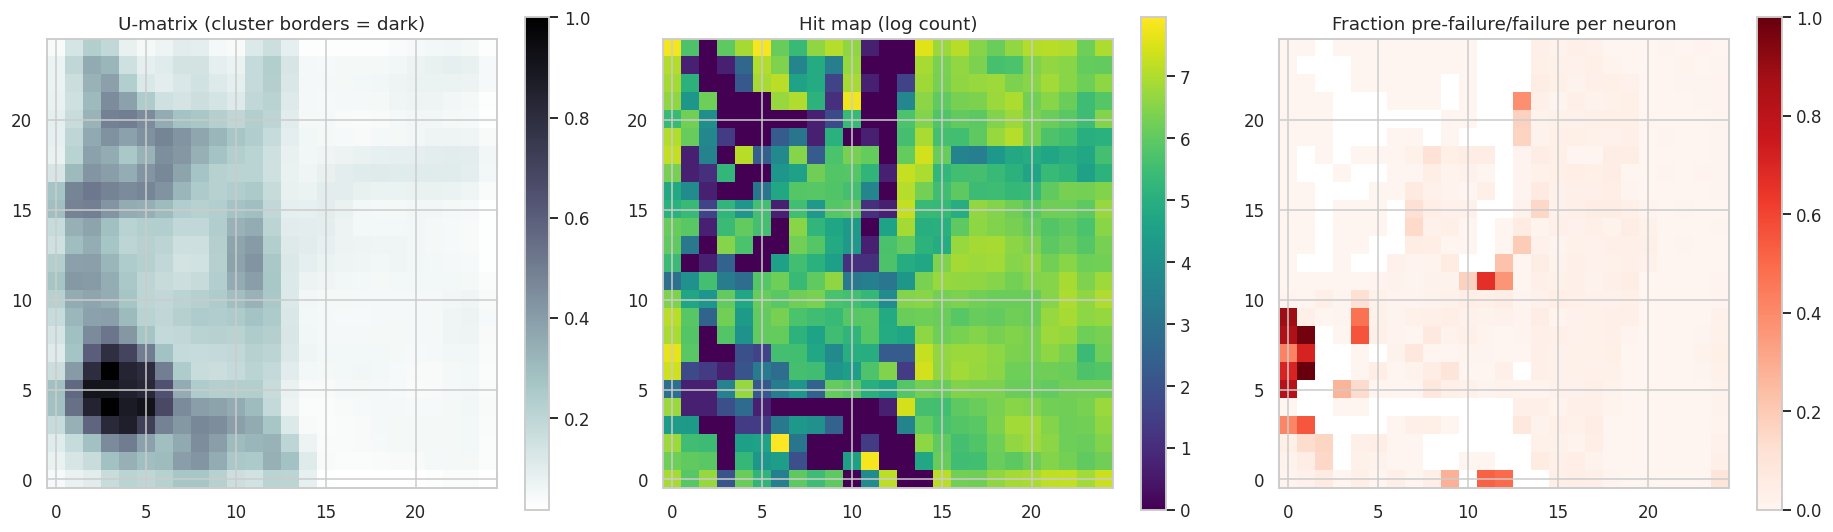

In [25]:
def som_winners(som, data, chunk=10000):
    """Vectorised best-matching unit for every row (same result as [som.winner(x) for x in data])."""
    W = som.get_weights(); g1, g2, d = W.shape
    Wf = W.reshape(-1, d); w2 = (Wf ** 2).sum(1)
    out = np.empty(len(data), dtype=np.int64)
    for i in range(0, len(data), chunk):
        c = data[i:i + chunk]
        out[i:i + chunk] = np.argmin(w2[None, :] - 2.0 * c @ Wf.T, axis=1)       # ||c||^2 is constant per row
    return np.column_stack(np.unravel_index(out, (g1, g2)))

winners = som_winners(som, X)                                  # (n, 2) grid coordinates for every minute
qe_som = np.linalg.norm(X - som.get_weights()[winners[:, 0], winners[:, 1]], axis=1)
Z_grid = winners + np.random.default_rng(SEED + 3).uniform(-0.35, 0.35, size=winners.shape)   # jittered, for plotting

flat = winners[:, 0] * GRID + winners[:, 1]
hits = np.bincount(flat, minlength=GRID * GRID).reshape(GRID, GRID)
n_abn_cell = np.bincount(flat, weights=(y > 0).astype(float), minlength=GRID * GRID).reshape(GRID, GRID)
frac_abn = np.where(hits >= 5, n_abn_cell / np.maximum(hits, 1), np.nan)

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
im0 = ax[0].imshow(som.distance_map().T, cmap="bone_r", origin="lower"); ax[0].set_title("U-matrix (cluster borders = dark)")
plt.colorbar(im0, ax=ax[0])
im1 = ax[1].imshow(np.log1p(hits).T, cmap="viridis", origin="lower"); ax[1].set_title("Hit map (log count)")
plt.colorbar(im1, ax=ax[1])
im2 = ax[2].imshow(frac_abn.T, cmap="Reds", origin="lower", vmin=0, vmax=1); ax[2].set_title("Fraction pre-failure/failure per neuron")
plt.colorbar(im2, ax=ax[2])
plt.tight_layout(); plt.show()

**Commentary.** Dark ridges in the U-matrix are borders between prototype groups, and the hit map shows where the data actually lands. The right panel shows the share of pre-failure/failure minutes per neuron and only colours neurons with at least 5 hits. Neurons with a high share mark regions where abnormal minutes concentrate. Because there are only four failure events, a high-share neuron can reflect one event's operating conditions and not a general fault signature.

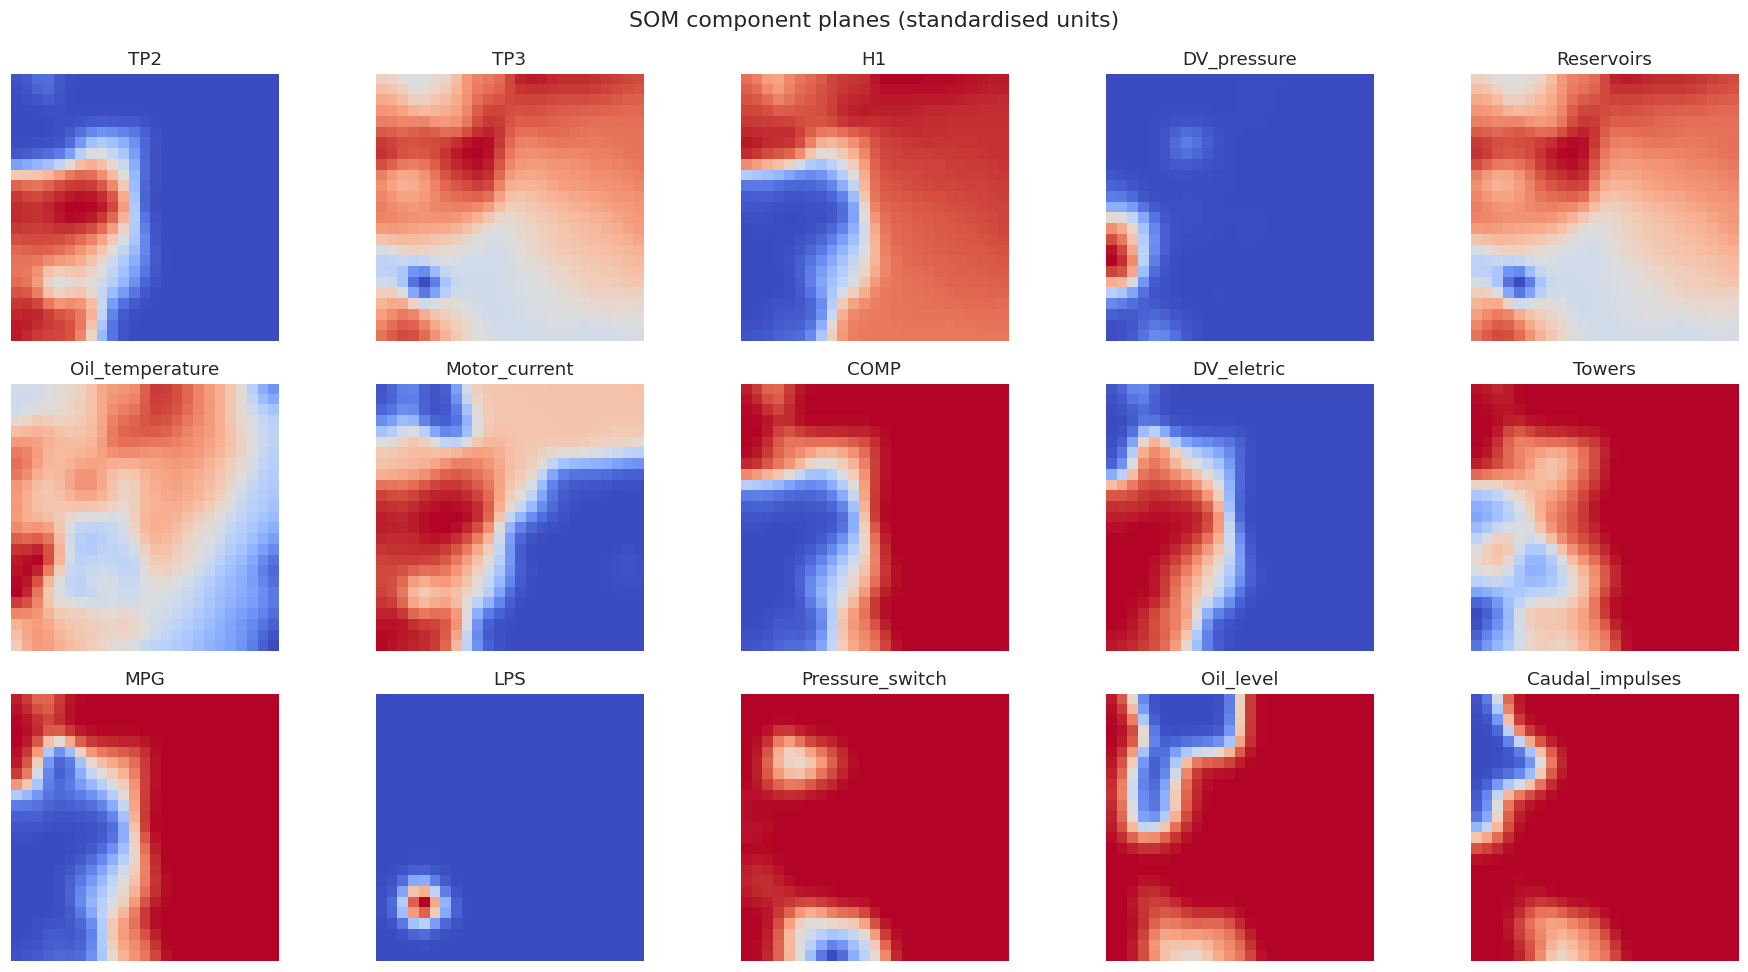

In [26]:
# Component planes: what does each region of the map mean?
W = som.get_weights()
fig, axes = plt.subplots(3, 5, figsize=(17, 9))
for ax, k, f in zip(axes.ravel(), range(len(FEATURES)), FEATURES):
    im = ax.imshow(W[:, :, k].T, cmap="coolwarm", origin="lower"); ax.set_title(f); ax.axis("off")
plt.suptitle("SOM component planes (standardised units)"); plt.tight_layout(); plt.show()

**Commentary.** Each panel shows one sensor's prototype value across the map. Smooth gradients show the map has organised itself along that sensor, and panels that look alike show redundant sensors. Compare these with the high-abnormal-share regions in the previous figure to see which sensors are extreme there.

,silhouette
k,
2,0.505
3,0.325
4,0.330
5,0.348
6,0.361
7,0.385
8,0.419


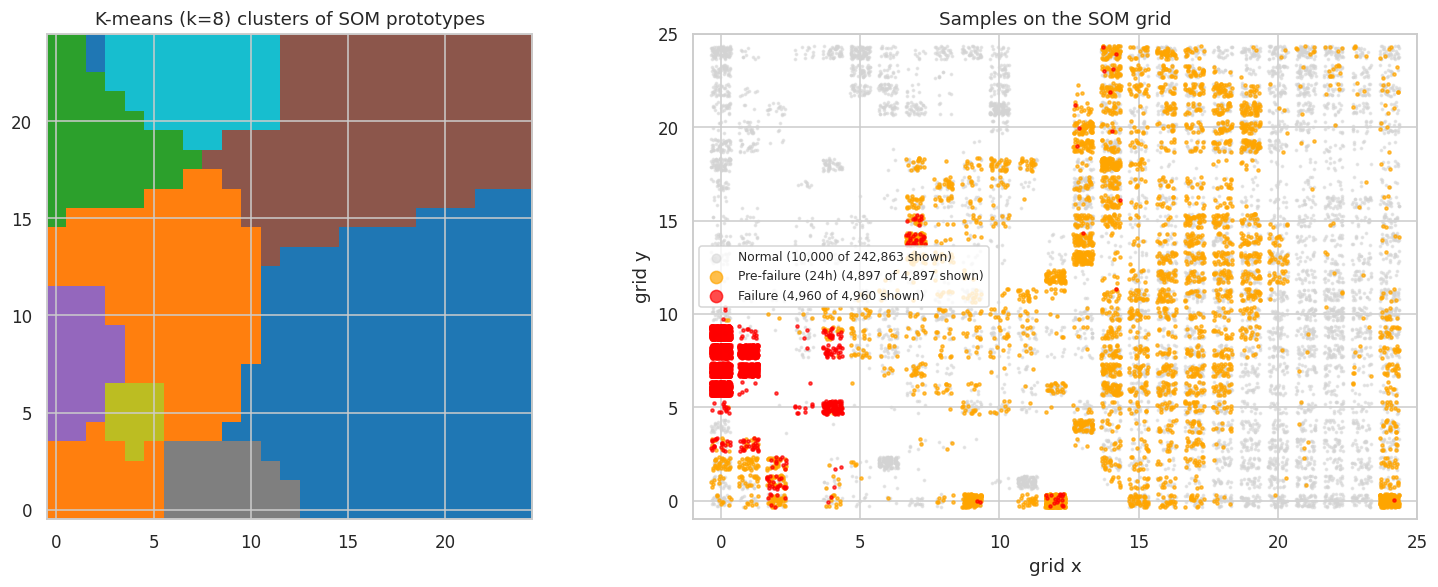

state,Failure,Normal,Pre-failure (24h)
SOM cluster,,,
0,0.000,0.983,0.017
1,0.007,0.965,0.028
2,0.000,0.999,0.001
3,0.464,0.533,0.003
4,0.000,0.978,0.022
5,0.002,0.902,0.095
6,0.131,0.864,0.005
7,0.000,1.000,0.000


In [27]:
# Clusters from k-means on the SOM prototypes. Silhouette on its own always rewards the coarsest split (k=2 just
# separates the two biggest blobs), so k is searched only in 3..8, which is the range where the map can show
# structure beyond one big split. k=2 is still printed for reference but is not eligible.
Wf = W.reshape(-1, X.shape[1])
sil = {k: silhouette_score(Wf, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Wf)) for k in range(2, 9)}
display(pd.Series(sil, name="silhouette").rename_axis("k").round(3).to_frame())
KM_K = max((k for k in sil if k >= 3), key=sil.get)
km = KMeans(n_clusters=KM_K, n_init=10, random_state=SEED).fit(Wf)
cluster_map = km.labels_.reshape(GRID, GRID)
cl_of_sample = cluster_map[winners[:, 0], winners[:, 1]]

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].imshow(cluster_map.T, cmap="tab10", origin="lower"); ax[0].set_title(f"K-means (k={KM_K}) clusters of SOM prototypes")
scatter_states(Z_grid, ax[1], "Samples on the SOM grid", "grid x", "grid y", per_class=10000)
ax[1].legend(markerscale=4, fontsize=8); ax[1].set_xlim(-1, GRID); ax[1].set_ylim(-1, GRID)
plt.tight_layout(); plt.show()

ct = pd.crosstab(pd.Series(cl_of_sample, name="SOM cluster"), pd.Series(y, name="state").map(names), normalize="index").round(3)
display(ct)

**Commentary.** The silhouette table is printed for k = 2 to 8, but k = 2 is not eligible because silhouette always favours the coarsest split, so the chosen k is the best of 3 to 8. The cross-tab is row-normalised per cluster: a cluster whose abnormal share is clearly above the overall abnormal rate is the interesting one. Shares for small clusters are noisy.

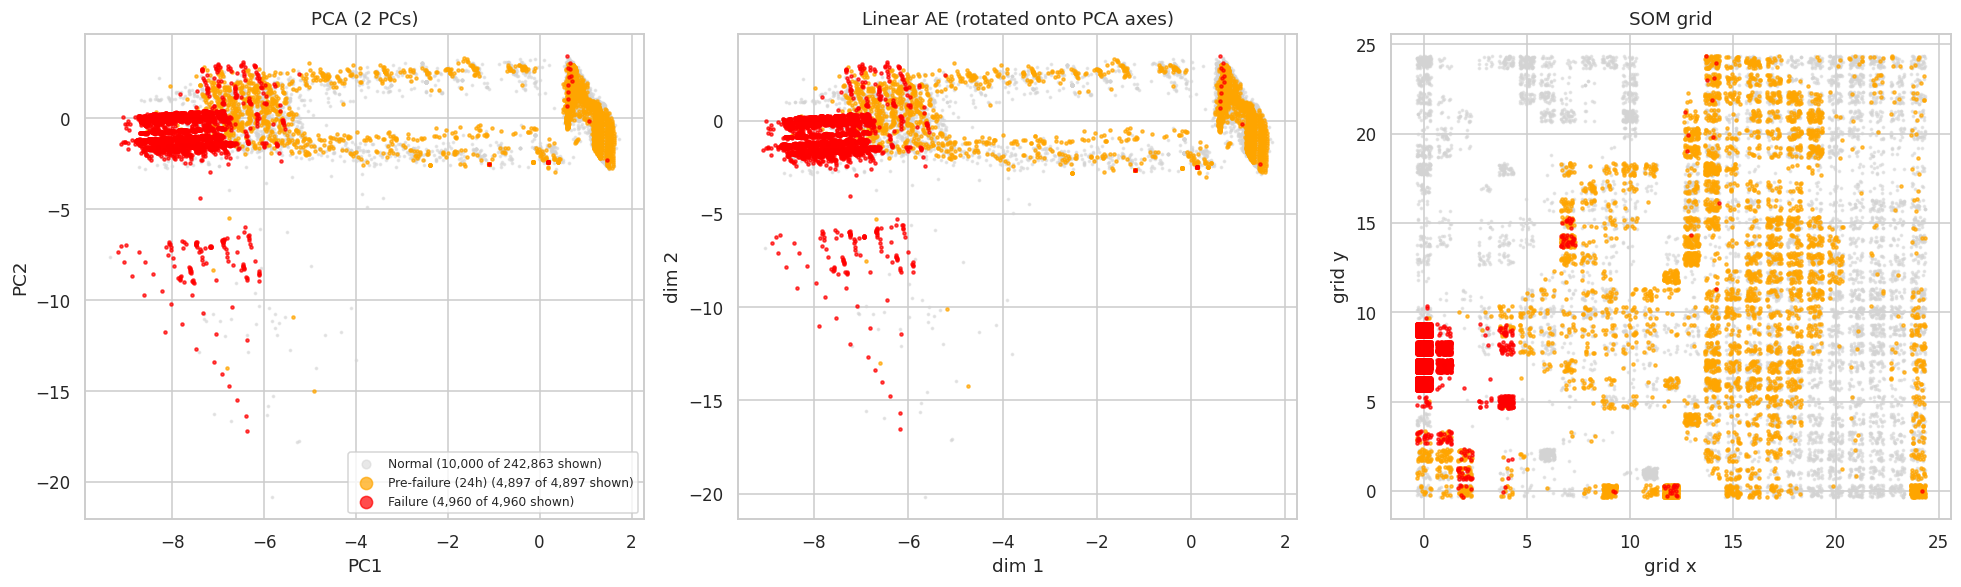

,Type,Recon./quantisation error (held-out normal),AUC abnormal vs normal,AUC failure vs normal
Method,,,,
PCA (2),"Linear, closed-form",0.537,0.730,0.959
Linear AE (2),"Linear, gradient-trained",0.531,0.729,0.959
SOM (25x25),"Non-linear, prototype-based",0.060,0.725,0.870


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
scatter_states(Z_pca, axes[0], "PCA (2 PCs)", "PC1", "PC2"); axes[0].legend(markerscale=4, fontsize=8)
scatter_states(Z_ae_aligned, axes[1], "Linear AE (rotated onto PCA axes)", "dim 1", "dim 2")
scatter_states(Z_grid, axes[2], "SOM grid", "grid x", "grid y")
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    "Method": ["PCA (2)", "Linear AE (2)", f"SOM ({GRID}x{GRID})"],
    "Type": ["Linear, closed-form", "Linear, gradient-trained", "Non-linear, prototype-based"],
    "Recon./quantisation error (held-out normal)": [mse_pca, mse_ae, np.mean(qe_som[test_mask] ** 2) / X.shape[1]],
    "AUC abnormal vs normal": [auc_abn(err_pca), auc_abn(err_ae), auc_abn(qe_som)],
    "AUC failure vs normal":  [auc_fail(err_pca), auc_fail(err_ae), auc_fail(qe_som)],
}).set_index("Method").round(3)
display(summary)

**Commentary.** The three panels use the same number of points per state. The table scores all three methods on the same held-out normal plus abnormal minutes. The SOM error is a quantization error (distance to the nearest prototype) and not a reconstruction MSE, so only the AUC columns are directly comparable across rows. The reconstruction column compares PCA and the AE only. AUCs near 0.5 mean no detection ability.

In [29]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import gymnasium as gym
from gymnasium import spaces
from gymnasium.envs.registration import registry
from scipy import stats
import time
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
SEED = 42   # same seed as Part A
print("Gymnasium", gym.__version__)

def smooth(x, w=200):
    # trailing moving average; the first w-1 episodes are NaN (no partial window -> no artificial spike at episode 0)
    return pd.Series(np.asarray(x, dtype=float)).rolling(w, min_periods=w).mean().values

Gymnasium 1.4.0


In [30]:
def eps_constant(eps):
    return lambda ep, n: eps

def eps_exp_decay(start=1.0, end=0.01, frac=0.5):
    # exponential decay that reaches `end` after `frac` of the training run
    def f(ep, n):
        return max(end, start * (end / start) ** (ep / (frac * n)))
    return f

def eps_linear(start=1.0, end=0.01, frac=0.5):
    def f(ep, n):
        return max(end, start - (start - end) * ep / (frac * n))
    return f

def argmax_tiebreak(q, rng):
    """Greedy action with RANDOM tie-breaking. np.argmax would always return action 0 on ties, e.g. for an
    unvisited (all-zero) state, which silently turns 'no information' into 'do nothing'."""
    best = np.flatnonzero(q >= q.max() - 1e-12)
    return int(best[0]) if len(best) == 1 else int(rng.choice(best))

def greedy_policy(Q, seed=0):
    rng = np.random.default_rng(seed)
    return lambda s: argmax_tiebreak(Q[s], rng)

def train_q(env, n_episodes, eps_fn, alpha=0.1, gamma=0.99, seed=SEED):
    rng = np.random.default_rng(seed)
    nS, nA = env.observation_space.n, env.action_space.n
    Q = np.zeros((nS, nA)); N = np.zeros((nS, nA), dtype=np.int64)          # N = real state-action visit counts
    returns, eps_hist = [], []
    for ep in range(n_episodes):
        eps = eps_fn(ep, n_episodes)
        s, _ = env.reset(seed=seed if ep == 0 else None)                    # seed the environment once, at the start
        done, G = False, 0.0
        while not done:
            a = int(rng.integers(nA)) if rng.random() < eps else argmax_tiebreak(Q[s], rng)
            s2, r, term, trunc, _ = env.step(a)
            target = r + (0.0 if term else gamma * Q[s2].max())             # bootstrap through time-limit truncation
            Q[s, a] += alpha * (target - Q[s, a]); N[s, a] += 1
            s, G = s2, G + r
            done = term or trunc
        returns.append(G); eps_hist.append(eps)
    return Q, np.array(returns), np.array(eps_hist), N

def evaluate(env, policy_fn, n_episodes=500, seed=1000):
    rets = []
    for i in range(n_episodes):
        s, _ = env.reset(seed=seed + i); done, G = False, 0.0
        while not done:
            s, r, term, trunc, _ = env.step(policy_fn(s)); G += r; done = term or trunc
        rets.append(G)
    return np.array(rets)

In [31]:
fl_env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True)
print(fl_env.unwrapped.desc.astype(str))
print("States:", fl_env.observation_space.n, "| Actions:", fl_env.action_space.n)

[['S' 'F' 'F' 'F']
 ['F' 'H' 'F' 'H']
 ['F' 'F' 'F' 'H']
 ['H' 'F' 'F' 'G']]
States: 16 | Actions: 4


**Commentary.** This is the standard slippery 4×4 FrozenLake: 16 states, 4 actions, `H` marks the holes (breakdowns) and `G` the goal. The slipperiness makes transitions random, which is why a good policy succeeds only about 74% of the time.

In [32]:
SEEDS = (0, 1, 2, 3, 4)          # every schedule is trained with several seeds; results are mean +- spread over seeds
N_FL = 20000
schedules_fl = {
    "greedy (ε=0)":        eps_constant(0.0),
    "constant ε=0.1":      eps_constant(0.1),
    "constant ε=0.5":      eps_constant(0.5),
    "exp. decay 1→0.01":   eps_exp_decay(1.0, 0.01, frac=0.5),
}
res_fl = {}
for name, fn in schedules_fl.items():
    t0 = time.time()
    runs = [train_q(fl_env, N_FL, fn, alpha=0.05, gamma=0.99, seed=sd) for sd in SEEDS]
    res_fl[name] = dict(Q=[r[0] for r in runs], R=np.array([r[1] for r in runs]), E=runs[0][2], N=[r[3] for r in runs])
    last = res_fl[name]["R"][:, -1000:].mean(axis=1)
    print(f"{name:20s} trained in {time.time()-t0:5.1f}s | last-1000 training success: {last.mean():.3f} ± {last.std(ddof=1):.3f} (over {len(SEEDS)} seeds)")

greedy (ε=0)         trained in  29.2s | last-1000 training success: 0.090 ± 0.082 (over 5 seeds)
constant ε=0.1       trained in  71.5s | last-1000 training success: 0.391 ± 0.020 (over 5 seeds)
constant ε=0.5       trained in  34.2s | last-1000 training success: 0.067 ± 0.008 (over 5 seeds)
exp. decay 1→0.01    trained in  94.0s | last-1000 training success: 0.684 ± 0.019 (over 5 seeds)


**Commentary.** The last-1000 training success is the success of the exploring behaviour policy, not of the learned Q-table. Greedy (ε=0) reaches 0.090 ± 0.082 across seeds and fails to learn. ε=0.1 reaches 0.391, constant ε=0.5 only 0.067 because it keeps acting randomly, and the decaying schedule reaches 0.684 because it explores early and exploits late.

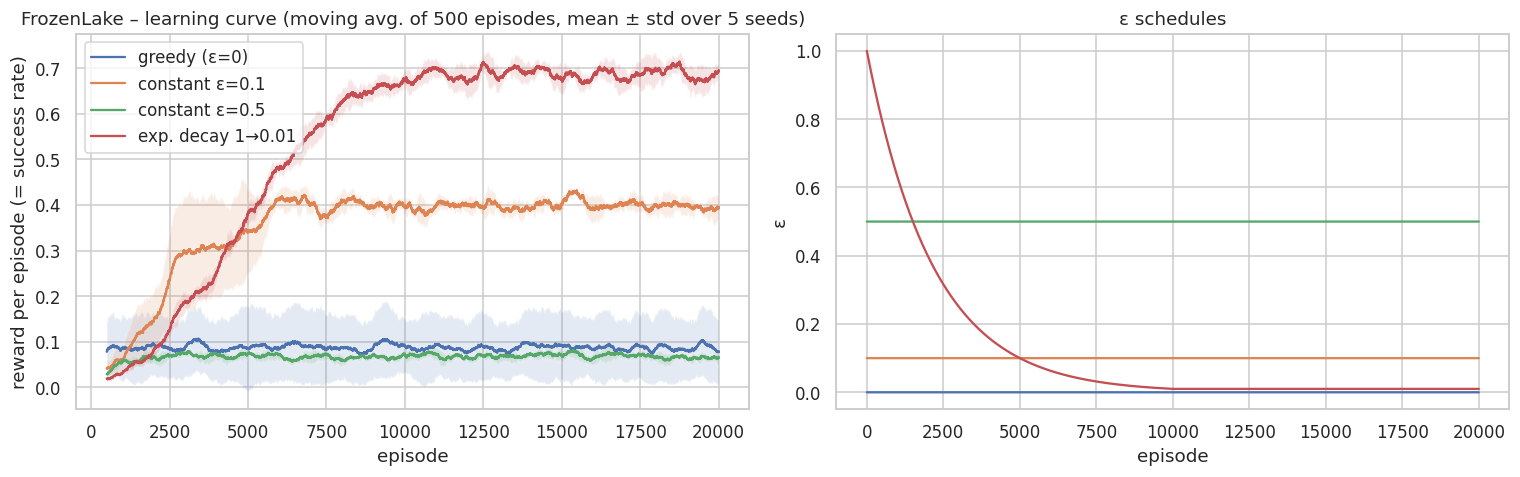

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, d in res_fl.items():
    curves = np.array([smooth(r, 500) for r in d["R"]]); m, sd = curves.mean(0), curves.std(0)
    ax[0].plot(m, label=name); ax[0].fill_between(range(len(m)), m - sd, m + sd, alpha=0.15)
    ax[1].plot(d["E"], label=name)
ax[0].set_title(f"FrozenLake – learning curve (moving avg. of 500 episodes, mean ± std over {len(SEEDS)} seeds)"); ax[0].set_xlabel("episode"); ax[0].set_ylabel("reward per episode (= success rate)")
ax[0].legend()
ax[1].set_title("ε schedules"); ax[1].set_xlabel("episode"); ax[1].set_ylabel("ε")
plt.tight_layout(); plt.show()

**Commentary.** The decaying schedule climbs as ε falls, ε=0.1 improves slowly, and ε=0.5 and greedy stay low. The shaded bands show the spread across the 5 training seeds. The right panel shows the ε schedules themselves.

In [34]:
# Evaluate each learned (greedy, random tie-breaking) policy without exploration.
# The schedule is SELECTED on validation episodes (seeds 5000+) and REPORTED on separate test episodes (seeds 1000+).
def eval_fl(Q, seed, n=2000):
    return evaluate(fl_env, greedy_policy(Q, seed=seed), n_episodes=n, seed=seed).mean()

rows = []
for name, d in res_fl.items():
    val  = np.array([eval_fl(Q, 5000) for Q in d["Q"]])
    test = np.array([eval_fl(Q, 1000) for Q in d["Q"]])
    rows.append((name, val.mean(), val.std(ddof=1) / np.sqrt(len(val)), test.mean(), test.std(ddof=1)))
fl_eval = pd.DataFrame(rows, columns=["Schedule", "Val success", "Val std. err", "Test success (mean over seeds)", "Test std across seeds"]).set_index("Schedule")
display(fl_eval.round(3))

best = fl_eval["Val success"].idxmax()                                       # unrounded validation scores
tied = fl_eval.index[fl_eval["Val success"] >= fl_eval.loc[best, "Val success"] - fl_eval.loc[best, "Val std. err"]].tolist()
print("Best schedule on validation episodes:", best)
if len(tied) > 1:
    print("Statistically tied with it (within 1 std. err.):", [t for t in tied if t != best])
print("Reference: the optimal policy on slippery 4x4 FrozenLake succeeds ≈ 74 % of the time.")

,Val success,Val std. err,Test success (mean over seeds),Test std across seeds
Schedule,,,,
greedy (ε=0),0.088,0.037,0.090,0.088
constant ε=0.1,0.723,0.007,0.723,0.005
constant ε=0.5,0.717,0.015,0.717,0.037
exp. decay 1→0.01,0.734,0.003,0.731,0.004


Best schedule on validation episodes: exp. decay 1→0.01
Reference: the optimal policy on slippery 4x4 FrozenLake succeeds ≈ 74 % of the time.


**Commentary.** Greedy test success is 0.090 for ε=0, 0.723 for ε=0.1, 0.717 for ε=0.5 and 0.731 for exponential decay, against about 0.74 for the optimal policy. The decaying schedule is best on the separate validation episodes (0.734 ± 0.003), and no schedule is tied with it under the one-standard-error rule. The practical result is that only pure greedy fails, and the three exploring schedules end within about 1.5 points of each other. Constant ε=0.5 still yields a good policy even though its training success was poor, so the cost of exploring and the quality of the learned Q are different things.

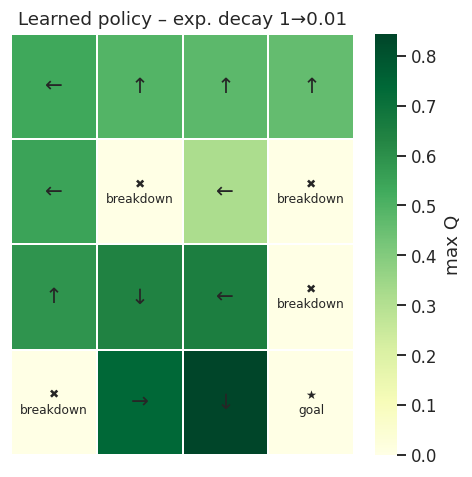

In [35]:
# Visualise the learned policy of the best schedule (seed-0 run); arrows = maintenance decision per health state.
# '?' = all Q-values equal (state never visited / no preference), NOT "go left".
Q = res_fl[best]["Q"][0]
arrows = {0: "←", 1: "↓", 2: "→", 3: "↑"}
desc = fl_env.unwrapped.desc.astype(str)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
vals = Q.max(axis=1).reshape(4, 4)
sns.heatmap(vals, annot=False, cmap="YlGn", cbar_kws={"label": "max Q"}, ax=ax, linewidths=1, linecolor="white")
for i in range(4):
    for j in range(4):
        s = i * 4 + j; ch = desc[i, j]
        pick = "?" if np.ptp(Q[s]) == 0 else arrows[int(np.argmax(Q[s]))]
        txt = {"H": "✖\nbreakdown", "G": "★\ngoal"}.get(ch, pick)
        ax.text(j + .5, i + .5, txt, ha="center", va="center", fontsize=14 if ch in "SF" else 8)
ax.set_title(f"Learned policy – {best}"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Commentary.** The arrows are the greedy action of the seed-0 run of the best schedule, and the colours show the max Q per state. On slippery ice the best moves often point along walls and away from holes and not straight at the goal, so arrows that look indirect are expected. A `?` would mean all Q-values were equal, so the agent has no preference there.

In [36]:
class FleetMaintenanceEnv(gym.Env):
    metadata = {"render_modes": ["ansi"]}
    N_VEH, MAX_WEAR = 3, 3
    N_WEAR_STATES = (MAX_WEAR + 1) ** N_VEH
    REVENUE = np.array([3.0, 2.5, 1.5, 0.5])   # revenue per step by wear level
    C_MAINT, C_BREAK = 4.0, 40.0               # planned vs unplanned cost
    P_DEG, P_FAIL = 0.25, 0.20                 # degradation prob. / breakdown prob. at critical wear

    def __init__(self, horizon=60, time_buckets=1, render_mode=None):
        super().__init__()
        # time_buckets=1 (default): the state is the wear of the 3 vehicles only (64 states).
        # time_buckets>1: the state also holds a time phase, state = wear + 64 * phase. The episode has a finite
        # horizon, so in principle the best action depends on the time left; whether the extra states pay off for a
        # tabular agent is tested explicitly in the time-phase ablation below.
        self.horizon, self.time_buckets, self.render_mode = horizon, time_buckets, render_mode
        self.observation_space = spaces.Discrete(self.N_WEAR_STATES * time_buckets)
        self.action_space = spaces.Discrete(self.N_VEH + 1)   # 0 = do nothing, i = maintain vehicle i
        self.w = np.zeros(self.N_VEH, dtype=int); self.t = 0
        self.info = dict(breakdowns=0, maintenances=0)

    def _obs(self):
        wear = int(sum(int(w) * (self.MAX_WEAR + 1) ** i for i, w in enumerate(self.w)))
        phase = min(self.t * self.time_buckets // self.horizon, self.time_buckets - 1)
        return wear + self.N_WEAR_STATES * phase

    @staticmethod
    def decode(s, n=3, base=4):
        # returns the wear tuple only (the low digits); the time phase is s // N_WEAR_STATES
        s = s % base ** n
        out = []
        for _ in range(n): out.append(s % base); s //= base
        return tuple(out)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.w = np.zeros(self.N_VEH, dtype=int); self.t = 0
        self.info = dict(breakdowns=0, maintenances=0)
        return self._obs(), {}

    def step(self, action):
        r, bay = 0.0, action - 1          # bay = index of vehicle in maintenance (or -1)
        for i in range(self.N_VEH):
            if i == bay:                              # planned maintenance
                r -= self.C_MAINT; self.w[i] = 0; self.info["maintenances"] += 1; continue
            if self.w[i] == self.MAX_WEAR and self.np_random.random() < self.P_FAIL:   # unplanned breakdown
                r -= self.C_BREAK; self.w[i] = 0; self.info["breakdowns"] += 1; continue
            r += self.REVENUE[self.w[i]]              # vehicle in service
            if self.w[i] < self.MAX_WEAR and self.np_random.random() < self.P_DEG:
                self.w[i] += 1
        self.t += 1
        return self._obs(), r, False, self.t >= self.horizon, dict(self.info)

    def render(self):
        return f"t={self.t:02d} wear={self.w.tolist()}"

# re-running this cell must not fail with a duplicate-registration error (and must pick up the new class)
if "FleetMaintenance-v0" in registry:
    del registry["FleetMaintenance-v0"]
gym.register(id="FleetMaintenance-v0", entry_point=FleetMaintenanceEnv)
env = gym.make("FleetMaintenance-v0")
print("Obs space:", env.observation_space, "| Action space:", env.action_space)

# quick sanity check with a random agent
s, _ = env.reset(seed=0); G = 0
for _ in range(60):
    s, r, term, trunc, info = env.step(env.action_space.sample()); G += r
print("Random-agent return over one episode:", round(G, 1), info)

Obs space: Discrete(64) | Action space: Discrete(4)
Random-agent return over one episode: 192.5 {'breakdowns': 0, 'maintenances': 41}


**Commentary.** The state is now the wear of the three vehicles only, so the observation space is 64 states with 4 actions. The random-agent line is a single episode and only checks that the environment runs. Whether a time feature in the state helps is tested in the ablation further down.

In [37]:
class Baselines:
    def __init__(self, kind, seed=0): self.kind, self.t, self.rng = kind, 0, np.random.default_rng(seed)
    def reset(self): self.t = 0
    def act(self, s):
        w = FleetMaintenanceEnv.decode(s)
        self.t += 1
        if self.kind == "never":      return 0
        if self.kind == "fixed":      return 1 + ((self.t // 4) % 3) if self.t % 4 == 0 else 0
        if self.kind == "threshold":  return (1 + int(np.argmax(w))) if max(w) >= 2 else 0
        if self.kind == "random":     return int(self.rng.integers(4))

def eval_baseline(kind, n=300, seed=2000):
    b, rets, bd, mt = Baselines(kind, seed=seed), [], [], []
    e = gym.make("FleetMaintenance-v0")
    for i in range(n):
        s, _ = e.reset(seed=seed + i); b.reset(); done, G = False, 0.0
        while not done:
            s, r, term, trunc, info = e.step(b.act(s)); G += r; done = term or trunc
        rets.append(G); bd.append(info["breakdowns"]); mt.append(info["maintenances"])
    return np.array(rets), np.mean(bd), np.mean(mt)

base_res = {k: eval_baseline(k) for k in ["never", "fixed", "threshold", "random"]}
pd.DataFrame({k: dict(mean_return=v[0].mean(), std=v[0].std(), breakdowns=v[1], maintenances=v[2]) for k, v in base_res.items()}).T.round(1)

,mean_return,std,breakdowns,maintenances
never,-43.7,67.0,9.4,0.0
fixed,184.2,71.4,3.4,15.0
threshold,366.7,17.9,0.0,18.8
random,121.8,50.3,1.3,44.9


**Commentary.** The hand-written baselines on the 300 test episodes: threshold 366.7, fixed schedule 184.2, random 121.8 and never maintain -43.7. Never maintaining is by far the worst because of frequent breakdowns, and threshold is the benchmark the learned agent has to match.

In [38]:
# 15,000 episodes: a 4,000-episode run was still improving (see the flattening check below).
N_FM = 15000
FM_SEEDS = (0, 1, 2, 3, 4)       # every schedule is trained with several seeds
schedules_fm = {
    "greedy (ε=0)":      eps_constant(0.0),
    "constant ε=0.1":    eps_constant(0.1),
    "constant ε=0.5":    eps_constant(0.5),
    "exp. decay 1→0.01": eps_exp_decay(1.0, 0.01, frac=0.5),
}
env_tr = gym.make("FleetMaintenance-v0")
res_fm = {}
for name, fn in schedules_fm.items():
    t0 = time.time()
    runs = [train_q(env_tr, N_FM, fn, alpha=0.1, gamma=0.95, seed=sd) for sd in FM_SEEDS]
    res_fm[name] = dict(Q=[r[0] for r in runs], R=np.array([r[1] for r in runs]), E=runs[0][2], N=[r[3] for r in runs])
    last = res_fm[name]["R"][:, -N_FM // 10:].mean(axis=1)
    print(f"{name:20s} trained in {time.time()-t0:5.1f}s | last-10% training return: {last.mean():7.1f} ± {last.std(ddof=1):5.1f} (over {len(FM_SEEDS)} seeds)")

greedy (ε=0)         trained in 106.4s | last-10% training return:   173.4 ±  64.5 (over 5 seeds)
constant ε=0.1       trained in 108.0s | last-10% training return:   345.6 ±   1.2 (over 5 seeds)
constant ε=0.5       trained in 104.5s | last-10% training return:   260.5 ±   0.7 (over 5 seeds)
exp. decay 1→0.01    trained in 107.8s | last-10% training return:   364.1 ±   0.7 (over 5 seeds)


**Commentary.** Each schedule now trains for 15,000 episodes with 5 seeds. The last-10% training return includes exploration, so it is lower than greedy performance for constant-ε schedules: 345.6 for ε=0.1 and 260.5 for ε=0.5. The decaying schedule reaches 364.1 ± 0.7, and greedy is unstable at 173.4 ± 64.5 across seeds.

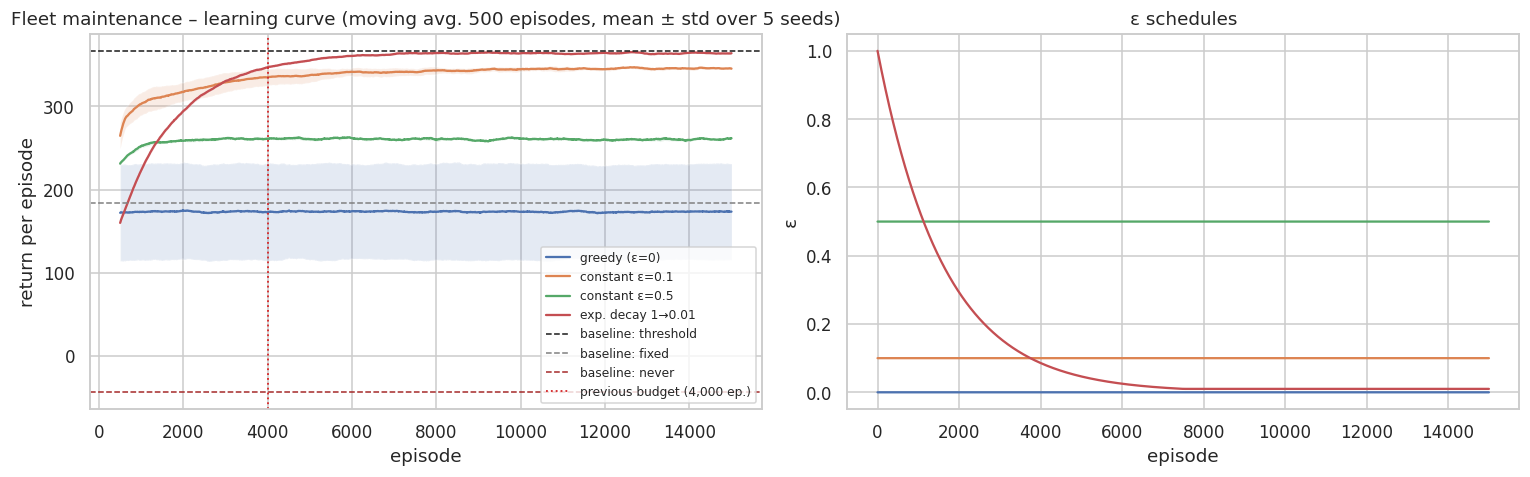

,at_ep_4000,prev_10pct,last_10pct,change,change_se,gain_since_ep_4000
schedule,,,,,,
greedy (ε=0),172.69,173.10,173.38,0.29,0.50,0.70
constant ε=0.1,334.95,345.84,345.56,-0.28,0.29,10.60
constant ε=0.5,260.87,260.31,260.52,0.21,0.58,-0.35
exp. decay 1→0.01,347.01,363.74,364.06,0.32,0.25,17.05


In [39]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, d in res_fm.items():
    curves = np.array([smooth(r, 500) for r in d["R"]]); m, sd = curves.mean(0), curves.std(0)
    ax[0].plot(m, label=name); ax[0].fill_between(range(len(m)), m - sd, m + sd, alpha=0.15)
    ax[1].plot(d["E"], label=name)
for k, c in [("threshold", "k"), ("fixed", "grey"), ("never", "brown")]:
    ax[0].axhline(base_res[k][0].mean(), ls="--", c=c, lw=1, label=f"baseline: {k}")
ax[0].axvline(4000, ls=":", c="tab:red", lw=1.2, label="previous budget (4,000 ep.)")
ax[0].set_title(f"Fleet maintenance – learning curve (moving avg. 500 episodes, mean ± std over {len(FM_SEEDS)} seeds)")
ax[0].set_xlabel("episode"); ax[0].set_ylabel("return per episode"); ax[0].legend(fontsize=8)
ax[1].set_title("ε schedules"); ax[1].set_xlabel("episode"); ax[1].set_ylabel("ε")
plt.tight_layout(); plt.show()

# Flattening check: mean training return in the last 10 % of the run vs the 10 % before it, per training seed.
# 'change' is the paired difference (mean ± std. err. over seeds); a flat curve has change ≈ 0 (within ~2 std. err.).
k10 = N_FM // 10
rows = []
for name, d in res_fm.items():
    R = d["R"]; last, prev = R[:, -k10:].mean(1), R[:, -2 * k10:-k10].mean(1); diff = last - prev
    rows.append(dict(schedule=name, at_ep_4000=R[:, 3500:4000].mean(), prev_10pct=prev.mean(), last_10pct=last.mean(),
                     change=diff.mean(), change_se=diff.std(ddof=1) / np.sqrt(len(diff)),
                     gain_since_ep_4000=last.mean() - R[:, 3500:4000].mean()))
display(pd.DataFrame(rows).set_index("schedule").round(2))

**Commentary.** The curves flatten well before the end. In the table, the last-10% training return differs from the 10% before it by at most 0.32 for every schedule, and each of those changes is within about 1 standard error. At episode 4,000 the decaying schedule was still 17.1 below its final level and ε=0.1 was 10.6 below, so the earlier run was under-trained and 15,000 episodes is enough. The red dotted line marks the old budget.

,mean_return,std_err,std_across_seeds,breakdowns_per_ep,maintenances_per_ep
"Q-learning, exp. decay 1→0.01",366.81,0.46,0.06,0.00,18.75
baseline: threshold,366.71,1.03,NaN,0.00,18.76
"Q-learning, constant ε=0.5",363.02,0.47,2.21,0.00,17.77
"Q-learning, constant ε=0.1",362.15,0.51,4.95,0.02,18.38
baseline: fixed,184.19,4.13,NaN,3.39,15.00
"Q-learning, greedy (ε=0)",171.58,1.70,63.61,0.14,45.95
baseline: random,121.80,2.91,NaN,1.26,44.94
baseline: never,-43.71,3.88,NaN,9.37,0.00


Validation return per schedule (used only to choose the schedule inspected below):
greedy (ε=0)         172.67
constant ε=0.1       361.03
constant ε=0.5       362.24
exp. decay 1→0.01    365.64
Chosen: exp. decay 1→0.01


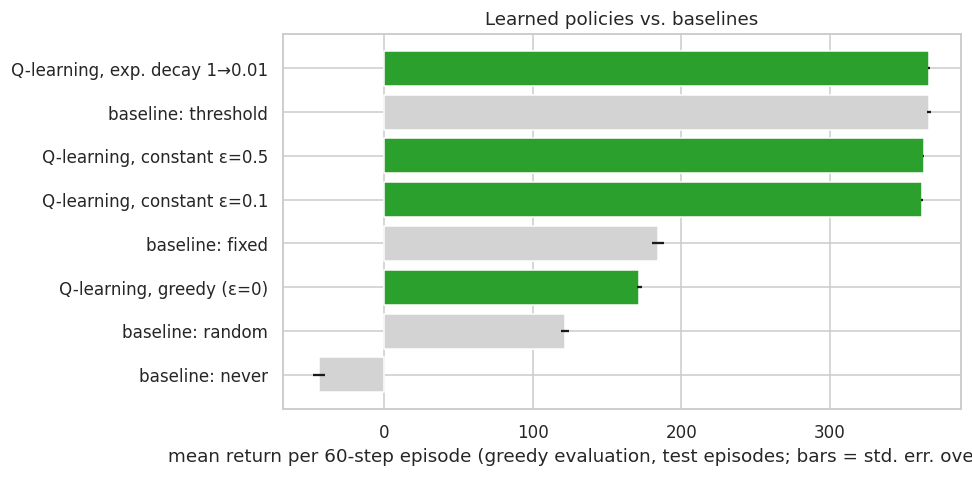

In [40]:
# Greedy evaluation (no exploration, random tie-breaking) of every learned policy vs. baselines.
# The best schedule is SELECTED on validation episodes (seeds 7000+) and REPORTED on different test episodes (seeds 2000+).
# ONE error-bar definition for every row: std_err = std of the per-episode return / sqrt(#episodes), over the same
# test episodes. For Q-learning the episodes of all training seeds are pooled; the extra column std_across_seeds
# (Q-learning only) shows the seed-to-seed spread of the mean return separately.
def eval_q(Q, n=300, seed=2000, time_buckets=1):
    e = gym.make("FleetMaintenance-v0", time_buckets=time_buckets); pol = greedy_policy(Q, seed=seed); rets, bd, mt = [], [], []
    for i in range(n):
        s, _ = e.reset(seed=seed + i); done, G = False, 0.0
        while not done:
            s, r, term, trunc, info = e.step(pol(s)); G += r; done = term or trunc
        rets.append(G); bd.append(info["breakdowns"]); mt.append(info["maintenances"])
    return np.array(rets), np.mean(bd), np.mean(mt)

def se(x): return np.std(x, ddof=1) / np.sqrt(len(x))

q_val, q_rows = {}, {}
for k, d in res_fm.items():
    q_val[k] = np.mean([eval_q(Q, seed=7000)[0].mean() for Q in d["Q"]])
    ev = [eval_q(Q, seed=2000) for Q in d["Q"]]
    pooled = np.concatenate([e[0] for e in ev])
    q_rows[f"Q-learning, {k}"] = dict(mean_return=pooled.mean(), std_err=se(pooled),
                                      std_across_seeds=np.std([e[0].mean() for e in ev], ddof=1),
                                      breakdowns_per_ep=np.mean([e[1] for e in ev]),
                                      maintenances_per_ep=np.mean([e[2] for e in ev]))
base_rows = {f"baseline: {k}": dict(mean_return=v[0].mean(), std_err=se(v[0]), std_across_seeds=np.nan,
                                    breakdowns_per_ep=v[1], maintenances_per_ep=v[2]) for k, v in base_res.items()}
summary = pd.DataFrame({**q_rows, **base_rows}).T.sort_values("mean_return", ascending=False).round(2)
display(summary)

best_fm = max(q_val, key=q_val.get)
print("Validation return per schedule (used only to choose the schedule inspected below):")
print(pd.Series(q_val).round(2).to_string()); print("Chosen:", best_fm)

plt.figure(figsize=(9, 4.5))
order = summary.index[::-1]
plt.barh(order, summary.loc[order, "mean_return"], xerr=summary.loc[order, "std_err"],
         color=["tab:green" if o.startswith("Q") else "lightgrey" for o in order])
plt.xlabel("mean return per 60-step episode (greedy evaluation, test episodes; bars = std. err. over episodes)")
plt.title("Learned policies vs. baselines"); plt.tight_layout(); plt.show()

**Commentary.** With the larger budget the exponential-decay agent reaches 366.81 ± 0.46 against 366.71 ± 1.03 for the threshold rule. The earlier gap (353 vs 367) was under-training, and the two now tie. The agent uses 18.75 maintenances per episode against 18.76 for the threshold rule and has no breakdowns, so it has essentially learned that rule. ε=0.5 (363.0) and ε=0.1 (362.2) are slightly lower, and greedy stays far lower at 171.6 with a seed-to-seed spread of 63.6. The error bars now have one meaning for every row: the standard error over per-episode returns, with the seed spread shown in a separate column. The agent matches the threshold rule but does not beat it here.

In [41]:
Qb, Nb = res_fm[best_fm]["Q"][0], res_fm[best_fm]["N"][0]        # seed-0 run of the chosen schedule
names_a = {0: "do nothing", 1: "service V1", 2: "service V2", 3: "service V3"}
NW = FleetMaintenanceEnv.N_WEAR_STATES

def act_name(Q, s):                      # all-equal Q-values = no preference (typically never visited), not "do nothing"
    return "no preference (unvisited)" if np.ptp(Q[s]) == 0 else names_a[int(np.argmax(Q[s]))]

examples = [(0,0,0), (1,0,0), (2,0,0), (3,0,0), (1,1,1), (2,2,0), (2,1,3), (3,3,3), (0,2,3), (1,3,2)]
rows = []
for w in examples:
    s = sum(wi * 4 ** i for i, wi in enumerate(w))
    rows.append(dict(wear_V1_V2_V3=str(w), best_action=act_name(Qb, s), visits=int(Nb[s].sum())))
print("Best schedule:", best_fm, "(seed-0 run)")
display(pd.DataFrame(rows).set_index("wear_V1_V2_V3"))

# policy as a function of the *maximum* wear in the fleet, over states that were actually visited
visited = np.flatnonzero(Nb.sum(axis=1) > 0)
print(f"Visited states: {len(visited)} of {Nb.shape[0]}")
pol_by_maxwear = pd.crosstab(
    pd.Series([max(FleetMaintenanceEnv.decode(s)) for s in visited], name="max wear in fleet"),
    pd.Series([act_name(Qb, s) for s in visited], name="action"))
display(pol_by_maxwear)

Best schedule: exp. decay 1→0.01 (seed-0 run)


,best_action,visits
wear_V1_V2_V3,,
"(0, 0, 0)",do nothing,95969
"(1, 0, 0)",do nothing,75917
"(2, 0, 0)",service V1,28815
"(3, 0, 0)",service V1,3948
"(1, 1, 1)",do nothing,61889
"(2, 2, 0)",service V2,5967
"(2, 1, 3)",service V3,50
"(3, 3, 3)",no preference (unvisited),0
"(0, 2, 3)",service V3,376


Visited states: 63 of 64


action,do nothing,service V1,service V2,service V3
max wear in fleet,,,,
0,1,0,0,0
1,7,0,0,0
2,0,6,8,5
3,0,10,14,12


**Commentary.** For the seed-0 run, the agent does nothing when the worst vehicle has wear 0 or 1 and services whenever the worst has wear 2 or 3, which is the same logic as the threshold rule. 63 of 64 states were visited, and the one unvisited state, (3, 3, 3), is shown as having no preference and not as "do nothing". Which vehicle is serviced when several are worn varies across states, which the crosstab shows by action.

In [42]:
# Trajectory of one greedy episode: what does the learned schedule look like?
e = gym.make("FleetMaintenance-v0"); s, _ = e.reset(seed=7); log = []
rng_traj = np.random.default_rng(SEED)
for t in range(30):
    a = argmax_tiebreak(Qb[s], rng_traj); wear_before = FleetMaintenanceEnv.decode(s)
    s, r, term, trunc, info = e.step(a)
    log.append(dict(t=t, wear_before=wear_before, action=names_a[a], reward=round(r, 1)))
display(pd.DataFrame(log).set_index("t").head(30))

,wear_before,action,reward
t,,,
0,"(0, 0, 0)",do nothing,9.0
1,"(0, 0, 0)",do nothing,9.0
2,"(1, 0, 0)",do nothing,8.5
3,"(2, 0, 0)",service V1,2.0
4,"(0, 0, 0)",do nothing,9.0
5,"(0, 0, 0)",do nothing,9.0
6,"(0, 0, 0)",do nothing,9.0
7,"(0, 0, 0)",do nothing,9.0
8,"(1, 1, 0)",do nothing,8.0


**Commentary.** In this one greedy episode the agent services a vehicle as soon as its wear reaches 2, so no vehicle reaches the breakdown-prone wear 3. A fully fresh fleet earns 9.0 per step, and a service step earns less because of the maintenance cost.

time_buckets= 4 trained in 109.3s
time_buckets=12 trained in 108.0s


,mean_return,std_err,std_across_seeds,breakdowns_per_ep,maintenances_per_ep
"Q-learning, 64 states (time_buckets=1)",366.81,0.46,0.06,0.0,18.75
"Q-learning, 256 states (time_buckets=4)",356.15,0.54,1.94,0.0,21.12
"Q-learning, 768 states (time_buckets=12)",319.22,0.67,2.63,0.0,29.48
baseline: threshold,366.71,1.03,NaN,0.0,18.76


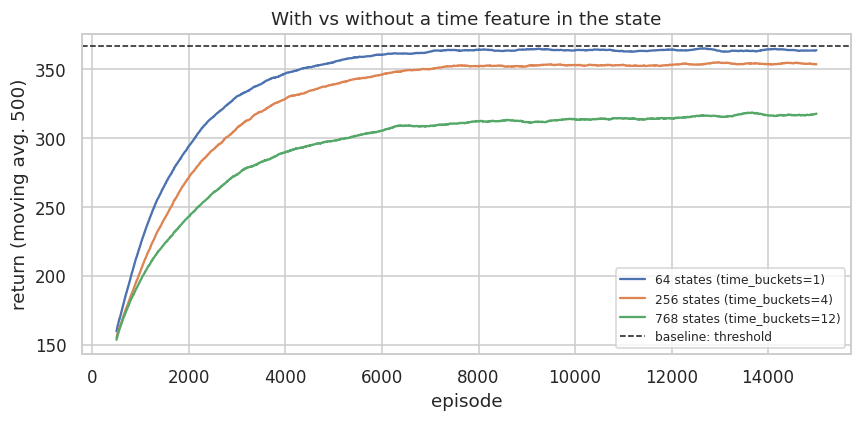

,share_service,n_states
steps 0-4,0.81,16
steps 5-9,0.94,31
steps 10-14,0.83,30
steps 15-19,0.72,32
steps 20-24,0.83,30
steps 25-29,0.87,30
steps 30-34,0.72,32
steps 35-39,0.81,32
steps 40-44,0.77,30
steps 45-49,0.79,29


In [43]:
# Time-phase ablation: the same agent (exp. decay, same budget and seeds) with and without a time feature in the state.
#   time_buckets = 1  -> 64 states (wear only)            [= the main run above]
#   time_buckets = 4  -> 256 states, phases of 15 steps   (too coarse to isolate the last few steps)
#   time_buckets = 12 -> 768 states, phases of 5 steps    (fine enough to see end-of-horizon behaviour)
TB_OPTIONS = (1, 4, 12)
fn_decay = schedules_fm["exp. decay 1→0.01"]
res_tb = {1: res_fm["exp. decay 1→0.01"]}                 # already trained
for tb in TB_OPTIONS[1:]:
    t0 = time.time(); env_tb = gym.make("FleetMaintenance-v0", time_buckets=tb)
    runs = [train_q(env_tb, N_FM, fn_decay, alpha=0.1, gamma=0.95, seed=sd) for sd in FM_SEEDS]
    res_tb[tb] = dict(Q=[r[0] for r in runs], R=np.array([r[1] for r in runs]), N=[r[3] for r in runs])
    print(f"time_buckets={tb:2d} trained in {time.time()-t0:5.1f}s")

rows = {}
for tb, d in res_tb.items():
    ev = [eval_q(Q, seed=2000, time_buckets=tb) for Q in d["Q"]]
    pooled = np.concatenate([e[0] for e in ev])
    rows[f"Q-learning, {NW * tb} states (time_buckets={tb})"] = dict(
        mean_return=pooled.mean(), std_err=se(pooled), std_across_seeds=np.std([e[0].mean() for e in ev], ddof=1),
        breakdowns_per_ep=np.mean([e[1] for e in ev]), maintenances_per_ep=np.mean([e[2] for e in ev]))
rows["baseline: threshold"] = dict(mean_return=base_res["threshold"][0].mean(), std_err=se(base_res["threshold"][0]),
                                   std_across_seeds=np.nan, breakdowns_per_ep=base_res["threshold"][1],
                                   maintenances_per_ep=base_res["threshold"][2])
display(pd.DataFrame(rows).T.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
for tb, d in res_tb.items():
    m = np.array([smooth(r, 500) for r in d["R"]]).mean(0); ax.plot(m, label=f"{NW * tb} states (time_buckets={tb})")
ax.axhline(base_res["threshold"][0].mean(), ls="--", c="k", lw=1, label="baseline: threshold")
ax.set_xlabel("episode"); ax.set_ylabel("return (moving avg. 500)"); ax.set_title("With vs without a time feature in the state"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Does the fine-grained agent learn "do not service shortly before the end"? Share of visited, critical-wear
# (max wear = 3) states in which the greedy action is a service action, per time phase (seed-0 run).
TBF = max(TB_OPTIONS); Qf, Nf = res_tb[TBF]["Q"][0], res_tb[TBF]["N"][0]
recs = [dict(phase=s // NW, service=int(np.argmax(Qf[s])) > 0) for s in range(Qf.shape[0])
        if Nf[s].sum() > 0 and max(FleetMaintenanceEnv.decode(s)) == 3 and np.ptp(Qf[s]) > 0]
end_effect = pd.DataFrame(recs).groupby("phase")["service"].agg(share_service="mean", n_states="size")
end_effect.index = [f"steps {p * 60 // TBF}-{(p + 1) * 60 // TBF - 1}" for p in end_effect.index]
display(end_effect.round(2))

**Commentary.** At equal budget and seeds, adding a time feature makes the agent worse: 366.81 with 64 states, 356.15 with 256 and 319.22 with 768, against 366.71 for the threshold rule. Maintenances per episode rise from 18.75 to 21.12 and 29.48, which fits with the extra states being too thinly visited, where zero-valued ties lead to unnecessary servicing. The end-of-horizon table for the fine (5-step) variant gives no clear drop in servicing at critical wear towards the end (0.81 in the last phase against 0.81 in the first). So even with fine buckets the agent has not learned "don't service just before the end", and the potential gain is only a few reward points per episode. The time feature is therefore left out of the main model, and this ablation is the evidence for that choice.

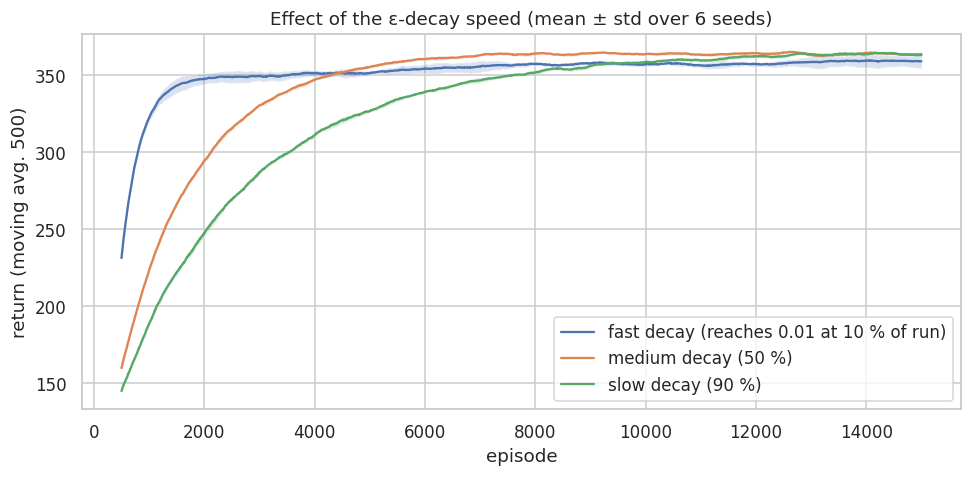

,final_return,final_se,early_return_first_25pct,early_se
fast decay (reaches 0.01 at 10 % of run),362.55,1.81,329.11,1.20
medium decay (50 %),366.77,0.05,280.17,0.35
slow decay (90 %),365.84,0.45,241.64,0.28


,a,b,diff_final,p_value
0,fast decay (reaches 0.01 at 10 % of run),medium decay (50 %),-4.211,0.068
1,fast decay (reaches 0.01 at 10 % of run),slow decay (90 %),-3.289,0.132
2,medium decay (50 %),slow decay (90 %),0.922,0.095


In [44]:
# Decay-speed sensitivity, re-run with the larger budget (same N_FM and 300 evaluation episodes as the main run) and
# more seeds. Reported: final greedy return, the early training return (first quarter of the run = how fast it
# learns), and Welch t-tests between the variants so that differences are judged against seed-to-seed noise.
SENS_SEEDS = tuple(range(6))
def run_many(fn, seeds=SENS_SEEDS, n_ep=N_FM, n_eval=300):
    curves, finals, early = [], [], []
    for sd in seeds:
        Q, R, _, _ = train_q(gym.make("FleetMaintenance-v0"), n_ep, fn, alpha=0.1, gamma=0.95, seed=sd)
        curves.append(smooth(R, 500)); finals.append(eval_q(Q, n=n_eval)[0].mean()); early.append(R[: n_ep // 4].mean())
    return np.array(curves), np.array(finals), np.array(early)

variants = {"fast decay (reaches 0.01 at 10 % of run)": eps_exp_decay(1.0, 0.01, 0.1),
            "medium decay (50 %)": eps_exp_decay(1.0, 0.01, 0.5),
            "slow decay (90 %)":   eps_exp_decay(1.0, 0.01, 0.9)}
fig, ax = plt.subplots(figsize=(9, 4.5)); sens, early_ret = {}, {}
for name, fn in variants.items():
    cur, fin, ear = run_many(fn); sens[name], early_ret[name] = fin, ear
    m, sd = cur.mean(0), cur.std(0)
    ax.plot(m, label=name); ax.fill_between(range(len(m)), m - sd, m + sd, alpha=0.2)
ax.set_xlabel("episode"); ax.set_ylabel("return (moving avg. 500)"); ax.set_title(f"Effect of the ε-decay speed (mean ± std over {len(SENS_SEEDS)} seeds)"); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame({k: dict(final_return=v.mean(), final_se=se(v), early_return_first_25pct=early_ret[k].mean(),
                              early_se=se(early_ret[k])) for k, v in sens.items()}).T.round(2))
vn = list(sens); pw = []
for i in range(len(vn)):
    for j in range(i + 1, len(vn)):
        t, p = stats.ttest_ind(sens[vn[i]], sens[vn[j]], equal_var=False)
        pw.append(dict(a=vn[i], b=vn[j], diff_final=sens[vn[i]].mean() - sens[vn[j]].mean(), p_value=p))
display(pd.DataFrame(pw).round(3))

**Commentary.** Early training return falls steadily with slower decay (329.1, 280.2, 241.6 for fast, medium and slow), which is expected because slow decay explores longer. Final greedy return is 362.55 ± 1.81 (fast), 366.77 ± 0.05 (medium) and 365.84 ± 0.45 (slow). None of the pairwise Welch tests is significant at 5% with 6 seeds (p = 0.068, 0.132 and 0.095). The earlier non-monotonic result (332, 311, 332) was therefore not a real pattern. The conclusion supported by the data is that decay speed changes how fast the agent learns and not where it ends up once training is long enough. Fast decay may be slightly less reliable at the end (largest standard error), but this is not established.

In [45]:
# State-space growth: why tabular Q-learning does not scale
rows = []
for n_veh in [3, 5, 10, 20, 50]:
    for levels in [4, 10]:
        rows.append(dict(vehicles=n_veh, wear_levels=levels, n_states=f"{float(levels)**n_veh:.2e}", n_actions=n_veh + 1))
display(pd.DataFrame(rows))

,vehicles,wear_levels,n_states,n_actions
0,3,4,6.40e+01,4
1,3,10,1.00e+03,4
2,5,4,1.02e+03,6
3,5,10,1.00e+05,6
4,10,4,1.05e+06,11
5,10,10,1.00e+10,11
6,20,4,1.10e+12,21
7,20,10,1.00e+20,21
8,50,4,1.27e+30,51
9,50,10,1.00e+50,51


**Commentary.** The number of states grows exponentially with the number of vehicles: 64 here, about a million for 10 vehicles with 4 wear levels, and about 10^12 for 20. A Q-table cannot cover that, and function approximation would be needed. These counts do not include any extra factor for a time feature.